# ♻️ EcoSort: Complete Project
**Applied Computer Vision** | Sustainability: Waste Sorting

| Part | What it does | Lessons |
|---|---|---|
| 0 | Setup and switches | – |
| 1 | Compare pre-trained models | L1, L4 |
| 2 | Train ResNet18: Experiment A and B, evaluate, optimise | L2, L3, L5/6, L7 |
| 3 | LoRA training, image generation, image processing (**needs NVIDIA GPU**) | L9, L10, L11 |
| 4 | Experiment C: retrain with synthetic images | L3 |
| 5 | Task 2 testing evidence: TorchScript check, consistency, per-class examples, "Unsure" cases, web photos | L7, L8 |
| 6 | Gradio app | L8 |

> **Dataset credit.** Images: *TrashNet* (Yang & Thung, 2016), 6 classes (cardboard, glass, metal, paper, plastic, trash). LoRA-generated images were produced by this project (base model: see Part 3).


## Part 0: Setup and switches

In [1]:
import sys, os, subprocess  # standard library: system info, OS access, running shell commands
from pathlib import Path  # Path = easy file/folder paths

# ---------- SWITCHES (edit these) ----------
RUN_LORA          = True    # Part 3: LoRA training + generation (auto-skipped if no NVIDIA GPU)
INSTALL_LORA_DEPS = True    # pip install diffusers/peft/etc. (pinned versions from L9)
LORA_AUTO_PICK    = True    # auto-pick LoRA training images from dataset_raw if the folder is empty
LORA_IMAGES_PER_CLASS = 10  # training images per class for LoRA (L9 used 10)
IMAGES_PER_CLASS  = 15       # synthetic images to generate per class
# --------------------------------------------

import torch  # PyTorch, the deep-learning library
HAS_GPU = torch.cuda.is_available()  # True if an NVIDIA GPU can be used
print("Python :", sys.version.split()[0])  # show the Python version
print("Torch  :", torch.__version__)  # show the PyTorch version
print("GPU    :", torch.cuda.get_device_name(0) if HAS_GPU else "None (CPU only)")  # show the GPU name, or say CPU only
if RUN_LORA and not HAS_GPU:  # LoRA needs a GPU, so check before running Part 3
    print("⚠️ No NVIDIA GPU found: Part 3 and Part 4 will be skipped.")  # warn the user that Part 3 and Part 4 will be skipped
    print("   (Stable Diffusion training on CPU is not practical. Use a GPU machine or Google Colab for Part 3.)")  # explain why (training Stable Diffusion on CPU is too slow)
    RUN_LORA = False  # switch the LoRA switch off so later cells skip themselves

Python : 3.12.10
Torch  : 2.11.0+cu128
GPU    : NVIDIA GeForce RTX 5050 Laptop GPU


## Part 1: Explore pre-trained models (L1, L4)
Output: `EcoSort_Files/artifacts/model_comparison.csv`

In [2]:
import time, random, shutil, json, copy, statistics, re, gc  # libraries for timing, random sampling, file copying, JSON, copying objects, statistics, regex, memory cleanup
import numpy as np  # NumPy for arrays and maths
import pandas as pd  # pandas for tables (DataFrames)
import torch  # PyTorch
import torchvision.transforms as T  # image transforms (resize, crop, normalise)
from torchvision import models  # ready-made pre-trained models such as ResNet18
from PIL import Image  # PIL to open and handle images
from ultralytics import YOLO  # YOLOv8 object detector

BASE_DIR  = Path("EcoSort_Files")  # root folder for the whole project
RAW_DIR   = BASE_DIR / "dataset_raw"  # folder holding the raw images, one sub-folder per class
ARTIFACTS = BASE_DIR / "artifacts"; ARTIFACTS.mkdir(parents=True, exist_ok=True)  # folder for saved models and tables; create it if missing
IMG_EXTS  = (".jpg", ".jpeg", ".png", ".webp")  # image file types that count as images
assert RAW_DIR.exists(), f"Put your class folders inside {RAW_DIR}"  # stop with a clear message if the dataset folder is missing

# Test images: use EcoSort_Files/test_images if present, else sample 8 from the dataset
TEST_DIR = BASE_DIR / "test_images"  # optional folder of hand-picked test images
imgs = sorted(p for p in TEST_DIR.iterdir() if p.suffix.lower() in IMG_EXTS) if TEST_DIR.exists() else []  # use the test images if the folder exists, otherwise an empty list
if not imgs:  # no test images were provided, so pick some automatically
    pool = sorted(p for p in RAW_DIR.rglob("*") if p.suffix.lower() in IMG_EXTS)  # list every image in the raw dataset
    random.seed(42); imgs = random.sample(pool, min(8, len(pool)))  # fix the random seed so the same 8 images are picked every run, then sample them
    print("ℹ️ No test_images folder, sampled from dataset_raw")  # tell the user the images were sampled automatically
print(f"Using {len(imgs)} test images")  # print how many test images are used
assert imgs, "No images found"  # stop if there are no images at all

resnet18  = models.resnet18(weights=models.ResNet18_Weights.DEFAULT).eval()  # load ResNet18 with ImageNet pre-trained weights, in evaluation mode
mobilenet = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT).eval()  # load MobileNetV2 with ImageNet pre-trained weights, in evaluation mode
yolo_cmp  = YOLO("yolov8n.pt")  # load the pre-trained YOLOv8-nano detector

tfm = T.Compose([T.Resize(256), T.CenterCrop(224), T.ToTensor(),  # preprocessing pipeline: resize to 256, centre-crop to 224, convert to tensor,
                 T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])  # normalise with the ImageNet mean and standard deviation
imagenet_labels = models.ResNet18_Weights.DEFAULT.meta["categories"]  # the 1000 ImageNet class names, used to read the model's guesses

ℹ️ No test_images folder, sampled from dataset_raw
Using 8 test images


In [3]:
def timed_classify(net):  # measure speed and top guess of a classifier over all test images
    times, tops = [], []  # lists to store the time and top label for each image
    for p in imgs:  # loop over each test image
        x = tfm(Image.open(p).convert("RGB")).unsqueeze(0)  # open the image, convert to RGB, preprocess it and add a batch dimension
        t0 = time.perf_counter()  # start the timer
        with torch.no_grad():  # no gradients needed for inference (faster, less memory)
            probs = torch.softmax(net(x), 1)[0]  # run the model and turn raw scores into probabilities
        times.append((time.perf_counter() - t0) * 1000)  # save the elapsed time in milliseconds
        tops.append(imagenet_labels[int(probs.argmax())])  # save the name of the most likely ImageNet class
    return sum(times) / len(times), tops  # return the average time and the list of top guesses

def n_params(net): return sum(p.numel() for p in net.parameters()) / 1e6  # count model parameters in millions

rows = []  # list that will become the comparison table
for name, net in [("ResNet18", resnet18), ("MobileNetV2", mobilenet)]:  # compare the two classification models
    ms, tops = timed_classify(net)  # run the timing function on this model
    rows.append({"Model": name, "Task": "Classification",  # add one table row: model name, task, size and speed
                 "Params (M)": round(n_params(net), 2), "Avg latency (ms)": round(ms, 1)})
    print(name, "-> ImageNet guesses:", tops[:5])  # print the first 5 guesses (ImageNet labels, not waste classes yet)

# YOLOv8n timing (L4)
t = []  # list to store YOLO timings
for p in imgs:  # time YOLO on every test image
    t0 = time.perf_counter()  # start the timer
    yolo_cmp.predict(str(p), conf=0.25, device="cpu", verbose=False)  # run YOLO detection on one image (confidence >= 0.25, CPU)
    t.append((time.perf_counter() - t0) * 1000)  # save the time in milliseconds
rows.append({"Model": "YOLOv8n", "Task": "Detection",  # add the YOLO row to the table
             "Params (M)": round(sum(p.numel() for p in yolo_cmp.model.parameters()) / 1e6, 2),
             "Avg latency (ms)": round(sum(t) / len(t), 1)})

comparison = pd.DataFrame(rows)  # turn the rows into a DataFrame
display(comparison)  # show the comparison table
comparison.to_csv(ARTIFACTS / "model_comparison.csv", index=False)  # save the table as a CSV for the report

ResNet18 -> ImageNet guesses: ['hammerhead', 'piggy bank', 'oil filter', 'mixing bowl', 'car wheel']
MobileNetV2 -> ImageNet guesses: ['ladle', 'carton', 'oil filter', 'croquet ball', 'mixing bowl']


,Model,Task,Params (M),Avg latency (ms)
0,ResNet18,Classification,11.69,28.9
1,MobileNetV2,Classification,3.50,15.3
2,YOLOv8n,Detection,3.16,44.7


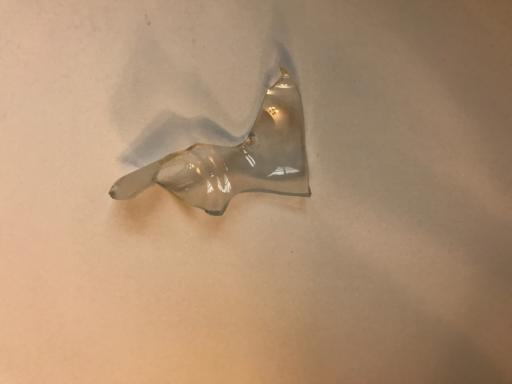

glass147.jpg -> []


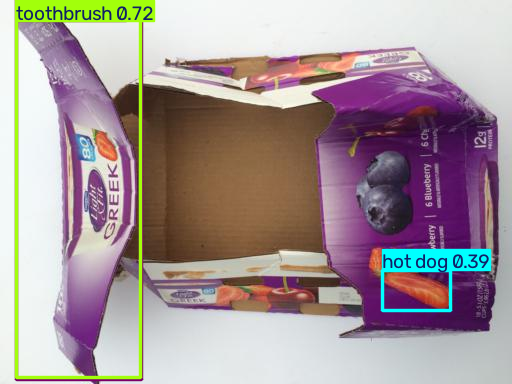

cardboard191.jpg -> ['toothbrush', 'hot dog', 'scissors']


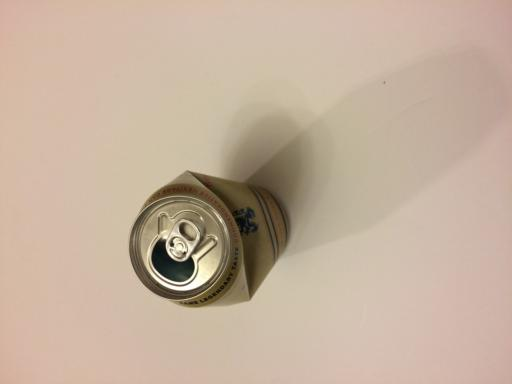

metal3.jpg -> []


In [4]:
# Show YOLOv8n detections on a few images (confirms the model works, L4)
from IPython.display import display  # function to show tables/images in the notebook
for p in imgs[:3]:  # loop over the first 3 test images
    res = yolo_cmp.predict(str(p), conf=0.25, device="cpu", verbose=False)[0]  # run YOLO and take the result for this image
    display(Image.fromarray(res.plot()[:, :, ::-1]))  # draw the detection boxes and show them (reverse colour order BGR to RGB)
    print(p.name, "->", [res.names[int(c)] for c in res.boxes.cls])  # print the image name and the objects YOLO found

## Part 2: Train ResNet18 (L2, L3) → evaluate (L5/6) → optimise (L7)

In [5]:
# Cell 1: Imports and configuration
import os, random, shutil, json, time, statistics, copy  # standard libraries for files, randomness, JSON, timing, statistics and copying
from pathlib import Path  # Path for file locations
import numpy as np  # NumPy
import pandas as pd  # pandas
import torch  # PyTorch
import torch.nn as nn  # neural-network building blocks
import torch.optim as optim  # optimisers such as Adam
from torch.utils.data import DataLoader  # DataLoader feeds images to the model in batches
from torchvision import datasets, transforms, models  # datasets, image transforms and pre-trained models from torchvision
import matplotlib.pyplot as plt  # matplotlib for charts
from sklearn.metrics import confusion_matrix, classification_report  # confusion matrix and precision/recall report from scikit-learn
from PIL import Image  # PIL for images

SEED = 42  # random seed so results can be repeated
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)  # set the seed for Python, NumPy and PyTorch
DEVICE = torch.device("cpu")  # train on CPU (change to cuda for GPU)

BASE_DIR  = Path("EcoSort_Files")  # root project folder
RAW_DIR   = BASE_DIR / "dataset_raw"  # raw images, one folder per class
DATA_DIR  = BASE_DIR / "dataset"  # where the train/val split is written
ARTIFACTS = BASE_DIR / "artifacts"  # where trained models are saved
FIG_DIR   = BASE_DIR / "figures"  # where charts are saved
for p in [ARTIFACTS, FIG_DIR]: p.mkdir(parents=True, exist_ok=True)  # create the artifacts and figures folders if missing

IMG_SIZE, BATCH_SIZE, EPOCHS, VAL_RATIO = 224, 16, 5, 0.2  # image size 224, batch of 16, 5 epochs, 20% of images for validation
IMG_EXTS = (".jpg", ".jpeg", ".png", ".webp")  # image file extensions accepted
print("✅ Config ready | device:", DEVICE)  # confirm the setup worked

✅ Config ready | device: cpu


In [6]:
# Cell 2: Split raw images into train/val (80/20)
if not RAW_DIR.exists():  # stop if the raw dataset folder does not exist
    raise FileNotFoundError(f"Put your class folders inside {RAW_DIR}")  # raise an error telling the user where to put the images
if DATA_DIR.exists(): shutil.rmtree(DATA_DIR)  # delete any old split so every run starts clean

for class_dir in sorted(RAW_DIR.iterdir()):  # go through each class folder (cardboard, glass, ...)
    if not class_dir.is_dir(): continue  # skip anything that is not a folder
    images = sorted(f for f in class_dir.iterdir() if f.suffix.lower() in IMG_EXTS)  # list the image files in the class folder
    random.shuffle(images)  # shuffle them randomly (seed is fixed, so it is repeatable)
    n_val = max(1, int(len(images) * VAL_RATIO))  # number of validation images = 20% of the class (at least 1)
    splits = {"val": images[:n_val], "train": images[n_val:]}  # first n_val shuffled images go to validation, the rest to training
    for split_name, files in splits.items():  # handle the train split, then the val split
        out = DATA_DIR / split_name / class_dir.name  # build the output folder, e.g. dataset/train/glass
        out.mkdir(parents=True, exist_ok=True)  # create it if it does not exist
        for f in files: shutil.copy(f, out / f.name)  # copy each image into its folder
    print(f"{class_dir.name:<10} train={len(splits['train']):>4}  val={len(splits['val']):>3}")  # print how many train and val images this class got
print("✅ Split complete ->", DATA_DIR)  # confirm the split finished

cardboard  train= 323  val= 80
glass      train= 401  val=100
metal      train= 328  val= 82
paper      train= 476  val=118
plastic    train= 386  val= 96
trash      train= 110  val= 27
✅ Split complete -> EcoSort_Files\dataset


Classes      : ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
class_to_idx : {'cardboard': 0, 'glass': 1, 'metal': 2, 'paper': 3, 'plastic': 4, 'trash': 5}
Train images : 2024 | Val images: 503


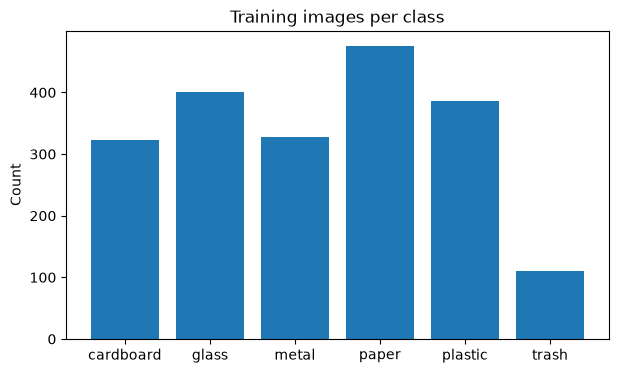

In [7]:
# Cell 3: Transforms, datasets, dataloaders
IMAGENET_MEAN = [0.485, 0.456, 0.406]  # mean RGB values used when ImageNet models were trained
IMAGENET_STD  = [0.229, 0.224, 0.225]  # standard deviation of the RGB values

train_tfms = transforms.Compose([  # training transforms (with augmentation):
    transforms.Resize(256),  # resize the shorter side to 256 pixels
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),  # random crop covering 80-100% of the image, resized to 224 (augmentation)
    transforms.RandomHorizontalFlip(p=0.5),  # randomly mirror half of the images (augmentation)
    transforms.ToTensor(),  # convert the image to a tensor
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),  # normalise colours the same way as ImageNet
])
val_tfms = transforms.Compose([  # validation transforms (no randomness):
    transforms.Resize(256),  # resize the shorter side to 256 pixels
    transforms.CenterCrop(IMG_SIZE),  # crop the centre 224x224 area
    transforms.ToTensor(),  # convert the image to a tensor
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),  # normalise colours the same way as ImageNet
])

train_ds = datasets.ImageFolder(DATA_DIR / "train", transform=train_tfms)  # load the training images; folder names become class labels
val_ds   = datasets.ImageFolder(DATA_DIR / "val",   transform=val_tfms)  # load the validation images
train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)  # loader that gives shuffled training batches
val_dl   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)  # loader that gives validation batches in a fixed order

print("Classes      :", train_ds.classes)  # print the class names
print("class_to_idx :", train_ds.class_to_idx)  # print the class name to number mapping
print(f"Train images : {len(train_ds)} | Val images: {len(val_ds)}")  # print how many images are in each set

# Class balance chart (for the report)
counts = {c: sum(1 for _, y in train_ds.samples if y == i) for i, c in enumerate(train_ds.classes)}  # count training images per class
plt.figure(figsize=(7, 4)); plt.bar(counts.keys(), counts.values())  # draw a bar chart of images per class
plt.title("Training images per class"); plt.ylabel("Count")  # add a title and axis label
plt.savefig(FIG_DIR / "class_balance.png", dpi=150, bbox_inches="tight"); plt.show()  # save the chart and show it

In [8]:
# Cell 4: Shared train / evaluate helpers (L3 logic)
def run_epoch_eval(model, dl, criterion):  # evaluate a model on a data loader (no training)
    model.eval()  # switch to evaluation mode (turns off dropout/batch-norm updates)
    loss_sum, correct, total = 0.0, 0, 0  # running totals of loss, correct predictions and number of images
    with torch.no_grad():  # no gradient tracking when evaluating
        for x, y in dl:  # loop over batches of images x and labels y
            x, y = x.to(DEVICE), y.to(DEVICE)  # move the batch to the CPU/GPU device
            out = model(x)  # run the model to get class scores
            loss_sum += criterion(out, y).item() * x.size(0)  # add this batch's loss (weighted by batch size)
            correct  += (out.argmax(1) == y).sum().item()  # count correct predictions (highest score equals the true label)
            total    += x.size(0)  # count the images seen
    return loss_sum / total, correct / total  # return average loss and accuracy

def train_model(model, optimizer, criterion, save_path, tag, bn_eval_modules):  # train a model and save the best checkpoint
    """Train for EPOCHS, save best checkpoint by val accuracy. Uses global train_dl."""
    history = {"epoch": [], "train_acc": [], "val_acc": [], "train_loss": [], "val_loss": []}  # dictionary to record accuracy and loss per epoch
    best_acc = -1.0  # best validation accuracy so far (starts below any real value)
    for epoch in range(1, EPOCHS + 1):  # repeat for each epoch
        model.train()  # switch to training mode
        for mod in bn_eval_modules:          # keep BatchNorm fixed in frozen parts
            for m in mod.modules():  # go through the frozen parts of the network
                if isinstance(m, nn.BatchNorm2d): m.eval()  # keep their batch-norm layers in evaluation mode so their statistics stay fixed
        loss_sum, correct, total = 0.0, 0, 0  # reset the training totals for this epoch
        for x, y in train_dl:  # loop over training batches
            x, y = x.to(DEVICE), y.to(DEVICE)  # move the batch to the device
            optimizer.zero_grad(set_to_none=True)  # clear old gradients from the previous step
            out  = model(x)  # forward pass: get predictions
            loss = criterion(out, y)  # compute the loss (how wrong the predictions are)
            loss.backward()  # backward pass: compute gradients
            optimizer.step()  # update the trainable weights
            loss_sum += loss.item() * x.size(0)  # add up the loss
            correct  += (out.argmax(1) == y).sum().item()  # add up the correct predictions
            total    += x.size(0)  # add up the images seen
        tr_loss, tr_acc = loss_sum / total, correct / total  # average training loss and accuracy for the epoch
        va_loss, va_acc = run_epoch_eval(model, val_dl, criterion)  # evaluate on the validation set
        for k, v in zip(history.keys(), [epoch, tr_acc, va_acc, tr_loss, va_loss]):  # store this epoch's numbers in the history
            history[k].append(v)
        print(f"[{tag}] Epoch {epoch}/{EPOCHS} | train_acc={tr_acc:.3f} val_acc={va_acc:.3f} | "  # print the epoch summary
              f"train_loss={tr_loss:.3f} val_loss={va_loss:.3f}")
        if va_acc > best_acc:  # if this is the best validation accuracy so far, save the model
            best_acc = va_acc  # remember the new best accuracy
            torch.save({"state_dict": model.state_dict(), "classes": train_ds.classes,  # save weights, class names and accuracy to a file
                        "class_to_idx": train_ds.class_to_idx, "val_acc": va_acc}, save_path)
            print(f"   💾 Saved best model ({va_acc:.3f}) -> {save_path.name}")  # tell the user a new best model was saved
    return history, best_acc  # return the training history and the best accuracy

In [9]:
# Cell 5: Experiment A - Feature extraction (train fc only)
num_classes = len(train_ds.classes)  # number of waste classes (6)
model_fe = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)  # load ResNet18 with pre-trained ImageNet weights
model_fe.fc = nn.Linear(model_fe.fc.in_features, num_classes)  # replace the last layer with a new one that outputs our 6 classes
for p in model_fe.parameters(): p.requires_grad = False  # freeze every layer (no training) ...
for p in model_fe.fc.parameters(): p.requires_grad = True  # ... then unfreeze only the new last layer (feature extraction)
model_fe = model_fe.to(DEVICE)  # move the model to the device

criterion    = nn.CrossEntropyLoss()  # loss function for multi-class classification
optimizer_fe = optim.Adam(model_fe.fc.parameters(), lr=1e-3)  # Adam optimiser that updates only the last layer (learning rate 0.001)
best_path_fe = ARTIFACTS / "expA_best.pth"  # file name for the best Experiment A model
hist_fe, best_acc_fe = train_model(model_fe, optimizer_fe, criterion, best_path_fe,  # train the model and save the best version
                                   tag="A-FeatExtract", bn_eval_modules=[model_fe])  # tag is the label shown in the logs; the model is passed so its batch-norm is kept fixed
print(f"\n🏁 Experiment A best val acc: {best_acc_fe:.3f}")  # print the best validation accuracy

[A-FeatExtract] Epoch 1/5 | train_acc=0.622 val_acc=0.751 | train_loss=1.035 val_loss=0.757
   💾 Saved best model (0.751) -> expA_best.pth
[A-FeatExtract] Epoch 2/5 | train_acc=0.782 val_acc=0.791 | train_loss=0.628 val_loss=0.613
   💾 Saved best model (0.791) -> expA_best.pth
[A-FeatExtract] Epoch 3/5 | train_acc=0.826 val_acc=0.809 | train_loss=0.521 val_loss=0.579
   💾 Saved best model (0.809) -> expA_best.pth
[A-FeatExtract] Epoch 4/5 | train_acc=0.845 val_acc=0.817 | train_loss=0.463 val_loss=0.551
   💾 Saved best model (0.817) -> expA_best.pth
[A-FeatExtract] Epoch 5/5 | train_acc=0.856 val_acc=0.811 | train_loss=0.415 val_loss=0.545

🏁 Experiment A best val acc: 0.817


In [10]:
# Cell 6: Experiment B - Fine-tuning (layer4 + fc, two learning rates)
model_ft = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)  # load a fresh pre-trained ResNet18 for Experiment B
model_ft.fc = nn.Linear(model_ft.fc.in_features, num_classes)  # replace the last layer with 6 outputs
for p in model_ft.parameters(): p.requires_grad = False  # freeze all layers
for p in model_ft.layer4.parameters(): p.requires_grad = True  # unfreeze layer4 (the last residual block) so it can adapt to waste
for p in model_ft.fc.parameters(): p.requires_grad = True  # unfreeze the new last layer
model_ft = model_ft.to(DEVICE)  # move the model to the device

optimizer_ft = optim.Adam([  # Adam with two learning rates:
    {"params": model_ft.layer4.parameters(), "lr": 3e-4},  # layer4 learns slowly (0.0003) to keep pre-trained knowledge
    {"params": model_ft.fc.parameters(),     "lr": 1e-3},  # the new last layer learns faster (0.001)
])
frozen_parts = [model_ft.conv1, model_ft.bn1, model_ft.layer1, model_ft.layer2, model_ft.layer3]  # early layers that stay frozen (their batch-norm is kept fixed)
best_path_ft = ARTIFACTS / "expB_best.pth"  # file name for the best Experiment B model
hist_ft, best_acc_ft = train_model(model_ft, optimizer_ft, criterion, best_path_ft,  # train and save the best version
                                   tag="B-FineTune", bn_eval_modules=frozen_parts)  # tag for the logs; frozen parts passed for batch-norm handling
print(f"\n🏁 Experiment B best val acc: {best_acc_ft:.3f}")  # print the best validation accuracy

[B-FineTune] Epoch 1/5 | train_acc=0.745 val_acc=0.827 | train_loss=0.710 val_loss=0.487
   💾 Saved best model (0.827) -> expB_best.pth
[B-FineTune] Epoch 2/5 | train_acc=0.903 val_acc=0.853 | train_loss=0.283 val_loss=0.433
   💾 Saved best model (0.853) -> expB_best.pth
[B-FineTune] Epoch 3/5 | train_acc=0.934 val_acc=0.877 | train_loss=0.189 val_loss=0.434
   💾 Saved best model (0.877) -> expB_best.pth
[B-FineTune] Epoch 4/5 | train_acc=0.954 val_acc=0.887 | train_loss=0.141 val_loss=0.410
   💾 Saved best model (0.887) -> expB_best.pth
[B-FineTune] Epoch 5/5 | train_acc=0.959 val_acc=0.853 | train_loss=0.112 val_loss=0.663

🏁 Experiment B best val acc: 0.887


In [11]:
# Cell 7: Comparison table + choose the model for the app
summary = pd.DataFrame({  # build a table comparing the two experiments
    "Experiment": ["A - Feature extraction", "B - Fine-tuning (layer4+fc)"],  # experiment names
    "Trainable layers": ["fc only", "layer4 + fc"],  # which layers were trained
    "Best val accuracy": [round(best_acc_fe, 3), round(best_acc_ft, 3)],  # best validation accuracy of each experiment
    "Final val loss": [round(hist_fe["val_loss"][-1], 3), round(hist_ft["val_loss"][-1], 3)],  # loss on the validation set after the last epoch
})
display(summary)  # show the table in the notebook
summary.to_csv(ARTIFACTS / "experiment_summary.csv", index=False)  # save the table as a CSV for the report
BEST_PATH = best_path_ft if best_acc_ft >= best_acc_fe else best_path_fe  # pick the better model (B if it is at least as accurate as A)
print("🏆 Best of A and B (used for this scorecard):", BEST_PATH.name, "| the app later uses the best of A/B/C/…")  # print which checkpoint will be used by the app

,Experiment,Trainable layers,Best val accuracy,Final val loss
0,A - Feature extraction,fc only,0.817,0.545
1,B - Fine-tuning (layer4+fc),layer4 + fc,0.887,0.663


🏆 Best of A and B (used for this scorecard): expB_best.pth | the app later uses the best of A/B/C/…


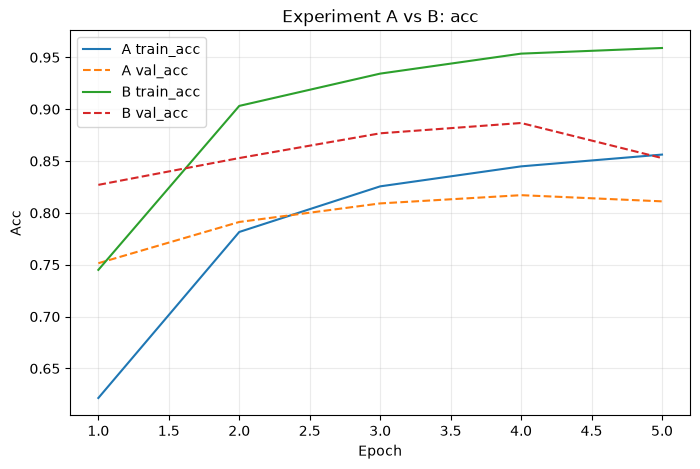

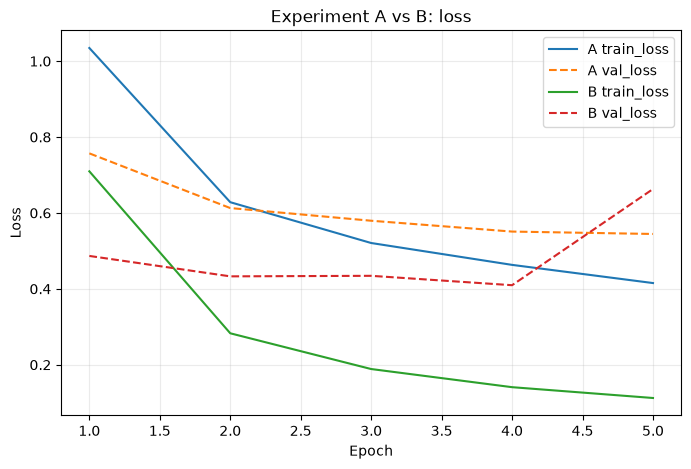

In [12]:
# Cell 8: Learning curves A vs B
def plot_compare(h_a, h_b):  # draw learning curves comparing experiment A and B
    for metric, fname in [("acc", "curves_accuracy.png"), ("loss", "curves_loss.png")]:  # draw one chart for accuracy and one for loss
        plt.figure(figsize=(8, 5))  # start a new figure
        for h, tag in [(h_a, "A"), (h_b, "B")]:  # plot both experiments on the same chart
            plt.plot(h["epoch"], h[f"train_{metric}"], label=f"{tag} train_{metric}")  # solid line = training curve
            plt.plot(h["epoch"], h[f"val_{metric}"], "--", label=f"{tag} val_{metric}")  # dashed line = validation curve
        plt.xlabel("Epoch"); plt.ylabel(metric.capitalize())  # label the axes
        plt.title(f"Experiment A vs B: {metric}")  # chart title
        plt.legend(); plt.grid(True, alpha=0.25)  # show the legend and a light grid
        plt.savefig(FIG_DIR / fname, dpi=150, bbox_inches="tight"); plt.show()  # save the chart as a PNG and show it
plot_compare(hist_fe, hist_ft)  # run the function with the histories of A and B

              precision    recall  f1-score   support

   cardboard      0.909     1.000     0.952        80
       glass      0.854     0.880     0.867       100
       metal      0.845     0.866     0.855        82
       paper      0.955     0.890     0.921       118
     plastic      0.892     0.865     0.878        96
       trash      0.760     0.704     0.731        27

    accuracy                          0.887       503
   macro avg      0.869     0.867     0.867       503
weighted avg      0.887     0.887     0.886       503



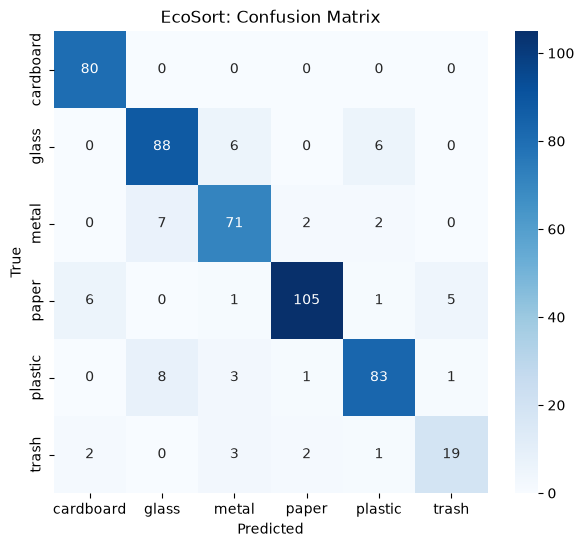

In [13]:
# Cell 9: Evaluation scorecard (accuracy, precision, recall, F1, confusion matrix)
# %pip install seaborn   # uncomment if seaborn is missing
import seaborn as sns  # seaborn for a nicer confusion-matrix heatmap

def load_model(path):  # load a saved model from a checkpoint file
    ckpt = torch.load(path, map_location=DEVICE)  # read the checkpoint (weights, class names, accuracy)
    m = models.resnet18(weights=None)  # create an empty ResNet18 (no pre-trained weights)
    m.fc = nn.Linear(m.fc.in_features, len(ckpt["classes"]))  # give it the 6-class output layer
    m.load_state_dict(ckpt["state_dict"])  # load the trained weights into it
    return m.to(DEVICE).eval(), ckpt["classes"]  # return the model in evaluation mode, plus the class names

model, CLASSES = load_model(BEST_PATH)  # load the chosen best model

y_true, y_pred = [], []  # lists for the true labels and the predictions
with torch.no_grad():  # no gradients needed for evaluation
    for x, y in val_dl:  # go through the validation images in batches
        y_pred += model(x.to(DEVICE)).argmax(1).cpu().tolist()  # save the model's predicted class for each image
        y_true += y.tolist()  # save the true class for each image

print(classification_report(y_true, y_pred, target_names=CLASSES, digits=3))  # print precision, recall and F1 for each class
with open(ARTIFACTS / "metrics_report.json", "w") as f:  # save the same report as a JSON file for the report
    json.dump(classification_report(y_true, y_pred, target_names=CLASSES, output_dict=True), f, indent=2)  # write the report dictionary to the file

cm = confusion_matrix(y_true, y_pred)  # count how often each true class is predicted as each class
plt.figure(figsize=(7, 6))  # start a new figure
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES)  # draw the confusion matrix as a heatmap with numbers
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("EcoSort: Confusion Matrix")  # label the axes and title
plt.savefig(FIG_DIR / "confusion_matrix.png", dpi=150, bbox_inches="tight"); plt.show()  # save the chart as a PNG and show it

Misclassified: 57 / 503


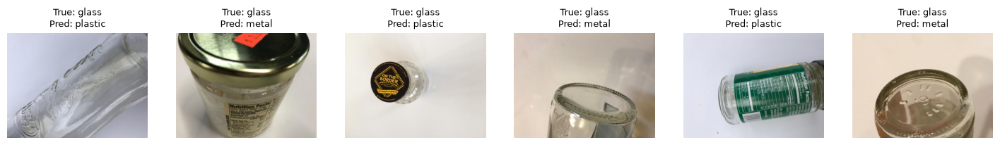

In [14]:
# Cell 10: Misclassified images (debugging evidence)
wrong = [(val_ds.samples[i][0], CLASSES[t], CLASSES[p])  # collect the validation images the model got wrong: (file path, true class, predicted class)
         for i, (t, p) in enumerate(zip(y_true, y_pred)) if t != p]  # only keep images where true and predicted labels differ
print(f"Misclassified: {len(wrong)} / {len(y_true)}")  # print how many images were misclassified
show = wrong[:6]  # look at the first 6 mistakes
if show:  # only draw if there is at least one
    fig, axes = plt.subplots(1, len(show), figsize=(3 * len(show), 3.4))  # make a row of subplots, one per mistake
    axes = [axes] if len(show) == 1 else axes  # if there is only one mistake, wrap the single plot in a list
    for ax, (path, true_c, pred_c) in zip(axes, show):  # loop over the plots and the mistakes together
        ax.imshow(Image.open(path).convert("RGB"))  # show the misclassified image
        ax.set_title(f"True: {true_c}\nPred: {pred_c}", fontsize=9); ax.axis("off")  # title shows the true class and what the model predicted; hide the axes
    plt.savefig(FIG_DIR / "misclassified.png", dpi=150, bbox_inches="tight"); plt.show()  # save the picture as a PNG and show it

In [15]:
# Cell 11: Baseline CPU latency + accuracy (L7)
def benchmark(model_fn, dl, n_runs=30):  # measure speed (latency) and accuracy of any model function
    x_single = next(iter(dl))[0][:1].to(DEVICE)  # take one single image from the validation loader
    for _ in range(5): model_fn(x_single)              # warm-up
    times = []  # list to store timings
    for _ in range(n_runs):  # repeat the timing 30 times for a stable average
        t0 = time.perf_counter(); model_fn(x_single)  # start the timer and run the model once
        times.append((time.perf_counter() - t0) * 1000)  # save the time in milliseconds
    correct, total = 0, 0  # counters for correct predictions and total images
    for x, y in dl:  # go through the whole validation set
        correct += (model_fn(x.to(DEVICE)).argmax(1).cpu() == y).sum().item(); total += y.size(0)  # add up correct predictions and images seen
    return {"mean_ms": round(statistics.mean(times), 2), "median_ms": round(statistics.median(times), 2),  # return mean and median time (ms)
            "p95_ms": round(sorted(times)[max(0, int(0.95 * len(times)) - 1)], 2),  # 95th-percentile time (ms), a 'worst case' speed
            "accuracy": round(correct / total, 3)}  # and the overall accuracy

@torch.no_grad()  # wrapper that runs the normal FP32 model without gradients
def fp32_fn(x): return model(x)

results = {"Baseline FP32": benchmark(fp32_fn, val_dl)}  # benchmark the baseline model and store the result
print(results["Baseline FP32"])  # print the baseline numbers

{'mean_ms': 24.46, 'median_ms': 24.47, 'p95_ms': 26.75, 'accuracy': 0.887}


In [16]:
# Cell 12: Optimisations - dynamic INT8 quantisation + TorchScript (L7)
# NOTE: dynamic quantisation only converts nn.Linear layers. ResNet18 has just one (fc, 512x6),
# so any speed difference vs FP32 is timing noise, not a real speed-up. Report it that way.
model_q = torch.quantization.quantize_dynamic(copy.deepcopy(model), {nn.Linear}, dtype=torch.qint8)  # INT8 quantisation: store the Linear layers' weights as 8-bit integers (smaller and often faster)
@torch.no_grad()  # wrapper for the quantised model without gradients
def quant_fn(x): return model_q(x)
results["Dynamic INT8"] = benchmark(quant_fn, val_dl)  # benchmark the quantised model

example = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)  # dummy input image used for tracing
ts_model = torch.jit.trace(model, example)  # TorchScript: convert the model to a faster, standalone graph
ts_model.save(str(ARTIFACTS / "ecosort_resnet18_ts.pt"))  # save the TorchScript model to a file for the app
@torch.no_grad()  # wrapper for the TorchScript model without gradients
def ts_fn(x): return ts_model(x)
results["TorchScript"] = benchmark(ts_fn, val_dl)  # benchmark the TorchScript model

opt_df = pd.DataFrame(results).T  # turn the three results into a table (one row per model)
display(opt_df)  # show the table
opt_df.to_csv(ARTIFACTS / "optimisation_results.csv")  # save it as a CSV for the report

C:\Users\ojpkv\AppData\Local\Temp\ipykernel_25744\3753866067.py:4: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  model_q = torch.quantization.quantize_dynamic(copy.deepcopy(model), {nn.Linear}, dtype=torch.qint8)  # INT8 quantisation: store the Linear layers' weights as 8-bit integers (smaller and often faster)


,mean_ms,median_ms,p95_ms,accuracy
Baseline FP32,24.46,24.47,26.75,0.887
Dynamic INT8,27.32,26.76,30.31,0.887
TorchScript,14.87,14.85,15.73,0.887


In [17]:
# Cell 13: Top-k helper (L7 A5), reused in the app
@torch.no_grad()  # no gradients needed for prediction
def predict_topk(model_obj, pil_img, k=3):  # return the top-k most likely classes with their probabilities
    x = val_tfms(pil_img.convert("RGB")).unsqueeze(0).to(DEVICE)  # preprocess the image and add a batch dimension
    probs = torch.softmax(model_obj(x), dim=1)[0]  # run the model and turn scores into probabilities
    top_p, top_i = torch.topk(probs, k)  # pick the k highest probabilities and their class numbers
    return [(CLASSES[i], float(p)) for p, i in zip(top_p, top_i)]  # return a list of (class name, probability) pairs
print(predict_topk(model, Image.open(val_ds.samples[0][0])))  # test the function on the first validation image

[('cardboard', 0.9906014204025269), ('paper', 0.009398214519023895), ('trash', 3.216520667592704e-07)]


## Part 3: LoRA training (L9) → generation (L10) → image processing (L11)
Needs an **NVIDIA GPU** (about 6 GB VRAM or more). Skipped automatically otherwise.

In [18]:
LORA_DIR     = BASE_DIR / "lora"  # folder for LoRA files
LORA_IMG_DIR = LORA_DIR / "train_images"      # LoRA training images + metadata.jsonl
LORA_OUT_TMP = LORA_DIR / "training_out"  # temporary folder for LoRA training output
LORA_TENSORS = LORA_DIR / "tensors"  # folder for the final LoRA weights
GEN_DIR      = LORA_DIR / "generated_images"  # folder for generated images
PROC_DIR     = LORA_DIR / "processed_images"  # folder for processed images
FINAL_DIR    = LORA_DIR / "outputs"  # folder for final outputs
LOG_DIR      = LORA_DIR / "logs"  # folder for training logs
for d in [LORA_IMG_DIR, LORA_TENSORS, GEN_DIR, FINAL_DIR, LOG_DIR]: d.mkdir(parents=True, exist_ok=True)  # create the folders if they do not exist
CATEGORIES = [c.lower() for c in train_ds.classes]  # class names in lowercase; used as the image categories
print("Classes for LoRA:", CATEGORIES)  # print the classes

Classes for LoRA: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


In [19]:
if RUN_LORA:  # only run if the LoRA switch is on
    if INSTALL_LORA_DEPS:  # only install packages if requested
        pkgs = ["diffusers==0.39.0", "transformers==5.13.0", "accelerate==1.14.0", "peft==0.19.1",  # pinned package versions so the code works the same every time
                "datasets==5.0.0", "safetensors", "ftfy", "Jinja2", "tensorboard"]
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--upgrade-strategy", "only-if-needed"] + pkgs, check=True)  # install them with pip in the current Python
        subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "-q", "torchao"])  # remove torchao because it can conflict with these versions
    import diffusers, transformers, accelerate, peft  # import the libraries to check the install worked
    print("diffusers", diffusers.__version__, "| transformers", transformers.__version__,  # print the installed versions
          "| accelerate", accelerate.__version__, "| peft", peft.__version__)   # copy into report Section 4
else:  # otherwise (LoRA off):
    print('⏭️ Skipped (LoRA steps are off or no GPU found).')  # tell the user this step was skipped

diffusers 0.39.0 | transformers 5.13.0 | accelerate 1.14.0 | peft 0.19.1


**LoRA training images.** Best practice: clean, single-item photos on a plain background. Auto-pick takes the first images from each class; for better results replace them in `EcoSort_Files/lora/train_images/` (named like `plastic_01.jpg`).

In [20]:
if RUN_LORA:  # only run if the LoRA switch is on
    existing = [p for p in LORA_IMG_DIR.iterdir() if p.suffix.lower() in IMG_EXTS]  # list images already in the LoRA training folder
    if not existing and LORA_AUTO_PICK:  # if the folder is empty and auto-pick is on, choose images automatically
        random.seed(42)  # fixed seed so the same images are chosen each time
        for cls_name in train_ds.classes:  # for each waste class ...
            pool = sorted(p for p in (DATA_DIR / 'train' / cls_name).iterdir() if p.suffix.lower() in IMG_EXTS)  # TRAIN split only, so no validation image can leak into the LoRA / Experiment C
            for i, p in enumerate(random.sample(pool, min(LORA_IMAGES_PER_CLASS, len(pool))), start=1):  # randomly pick a few (10 by default) and number them from 1
                shutil.copy(p, LORA_IMG_DIR / f"{cls_name.lower()}_{i:02d}{p.suffix.lower()}")  # copy each into the LoRA folder, named like glass_01.jpg
        print("✅ Auto-picked LoRA training images")  # tell the user the images were picked
    existing = sorted(p for p in LORA_IMG_DIR.iterdir() if p.suffix.lower() in IMG_EXTS)  # list the final training images
    import hashlib  # leakage check: make sure no LoRA image is a validation image
    md5 = lambda p: hashlib.md5(p.read_bytes()).hexdigest()
    val_hashes = {md5(p) for p in (DATA_DIR / 'val').rglob('*') if p.suffix.lower() in IMG_EXTS}
    leaked = [p.name for p in existing if md5(p) in val_hashes]
    if leaked: raise RuntimeError(f"{len(leaked)} LoRA images are validation images ({leaked[:5]}...). Delete {LORA_IMG_DIR} and re-run this cell.")
    print("✅ No LoRA training image is a validation image")
    print(f"LoRA training images: {len(existing)}")  # print how many there are
    assert existing, f"Add images to {LORA_IMG_DIR}"  # stop if the folder is still empty
else:  # otherwise (LoRA off):
    print('⏭️ Skipped (LoRA steps are off or no GPU found).')  # tell the user this step was skipped

✅ Auto-picked LoRA training images
✅ No LoRA training image is a validation image
LoRA training images: 60


In [21]:
if RUN_LORA:  # only run if the LoRA switch is on
    from collections import Counter  # Counter counts how many captions per class
    ITEM_PHRASE = {  # plain-English description of each class, used in the captions
        "cardboard": "flattened piece of cardboard", "glass": "empty glass bottle",
        "metal": "empty metal can", "paper": "sheet of crumpled paper",
        "plastic": "empty plastic bottle", "trash": "piece of general rubbish",
    }
    def phrase(c): return ITEM_PHRASE.get(c, c.replace("_", " ") + " item")  # function: get the phrase for a class (fallback if unknown)

    records, cap_counts, bad = [], Counter(), []  # lists for caption records, per-class counts and badly named files
    for p in sorted(LORA_IMG_DIR.iterdir()):  # go through every training image
        if p.suffix.lower() not in IMG_EXTS: continue  # skip files that are not images
        cls_name = re.sub(r"_\d+$", "", p.stem).lower()  # get the class from the file name, e.g. glass_01 -> glass
        if cls_name not in CATEGORIES: bad.append(p.name); continue  # remember files with unknown class names
        caption = (f"a ecosort studio product photo of one {phrase(cls_name)}, full object visible, "  # build the caption: the same style for every class
                   "centered on a plain white background, sharp focus, realistic photography")
        records.append({"file_name": p.name, "text": caption}); cap_counts[cls_name] += 1  # save the file name and caption as one record
    if bad: raise ValueError(f"Rename these files like classname_01.jpg: {bad}")  # stop if any file name does not follow the classname_01.jpg pattern
    with open(LORA_IMG_DIR / "metadata.jsonl", "w", encoding="utf-8") as f:  # write metadata.jsonl, which the training script reads
        for r in records: f.write(json.dumps(r, ensure_ascii=False) + "\n")  # one JSON line per image
    print(f"✅ {len(records)} captions written")  # print how many captions were written
    for c in CATEGORIES: print(f"   {c:<12}: {cap_counts.get(c, 0)}")  # print how many images each class has
else:  # otherwise (LoRA off):
    print('⏭️ Skipped (LoRA steps are off or no GPU found).')  # tell the user this step was skipped

✅ 60 captions written
   cardboard   : 10
   glass       : 10
   metal       : 10
   paper       : 10
   plastic     : 10
   trash       : 10


In [22]:
if RUN_LORA:  # only run if the LoRA switch is on
    # Train the LoRA (same hyperparameters as L9)
    PRETRAINED = "stable-diffusion-v1-5/stable-diffusion-v1-5"  # base model that LoRA adapts: Stable Diffusion 1.5
    RESOLUTION, LR, LR_SCHEDULER = 512, 5e-5, "cosine"  # image size 512, learning rate, cosine learning-rate schedule
    LR_WARMUP_STEPS, MAX_STEPS = 50, 400  # 50 warm-up steps, 400 training steps in total
    LORA_RANK, SNR_GAMMA = 8, 5.0  # LoRA rank 8 (size of the adapter), SNR loss weighting
    CHECKPOINT_STEPS, LORA_SEED = 100, 42  # save a checkpoint every 100 steps, random seed 42

    # Get the matching diffusers training script
    DIFFUSERS_ROOT = LORA_DIR / "diffusers"  # folder where the diffusers code is stored
    TRAINING_SCRIPT = DIFFUSERS_ROOT / "examples" / "text_to_image" / "train_text_to_image_lora.py"  # path of the official LoRA training script
    if not TRAINING_SCRIPT.exists():  # download the script only if we do not have it yet
        if DIFFUSERS_ROOT.exists(): shutil.rmtree(DIFFUSERS_ROOT, ignore_errors=True)  # remove a broken partial download first
        subprocess.run(["git", "clone", "--quiet", "--depth", "1", "--branch", "v0.39.0",  # clone the diffusers repo (version v0.39.0, only the latest files)
                        "https://github.com/huggingface/diffusers.git", str(DIFFUSERS_ROOT)], check=True)
    assert TRAINING_SCRIPT.exists(), "Training script missing (is git installed?)"  # stop with a message if the script is still missing

    if LORA_OUT_TMP.exists(): shutil.rmtree(LORA_OUT_TMP, ignore_errors=True)  # delete old training output
    LORA_OUT_TMP.mkdir(parents=True)  # create a fresh output folder
    cmd = [sys.executable, "-m", "accelerate.commands.launch", str(TRAINING_SCRIPT),  # build the training command as a list of arguments:
        f"--pretrained_model_name_or_path={PRETRAINED}", f"--train_data_dir={LORA_IMG_DIR}",  # base model
        "--image_column=image", "--caption_column=text",  # image column and caption column in the dataset
        f"--output_dir={LORA_OUT_TMP}", f"--logging_dir={LOG_DIR}",  # where to save results and logs
        f"--resolution={RESOLUTION}", "--center_crop",  # image size and centre-crop
        "--train_batch_size=1", "--gradient_accumulation_steps=4", "--gradient_checkpointing",  # batch of 1, accumulate 4 steps, save memory with gradient checkpointing
        f"--learning_rate={LR}", f"--lr_scheduler={LR_SCHEDULER}",  # learning rate and scheduler
        f"--lr_warmup_steps={LR_WARMUP_STEPS}", f"--max_train_steps={MAX_STEPS}",  # warm-up steps and total training steps
        f"--rank={LORA_RANK}", f"--snr_gamma={SNR_GAMMA}", "--mixed_precision=fp16",  # LoRA rank, loss weighting and half-precision (fp16) training
        f"--checkpointing_steps={CHECKPOINT_STEPS}", "--checkpoints_total_limit=2",  # checkpoint settings
        f"--seed={LORA_SEED}", "--dataloader_num_workers=0", "--report_to=tensorboard"]  # random seed, no extra workers, log to TensorBoard
    print("🚀 Training... (this can take a while; the model downloads on first run)")  # tell the user training has started
    log_path = LOG_DIR / "train_stdout_stderr.log"  # file for the training log
    with open(log_path, "w", encoding="utf-8") as lf:  # open the log file for writing
        result = subprocess.run(cmd, stdout=lf, stderr=subprocess.STDOUT, text=True)  # run training; send its output into the log file
    print("Exit code:", result.returncode)  # print the exit code (0 = success)
    print("".join(open(log_path, encoding="utf-8").readlines()[-25:]))  # show the last 25 log lines

    src = LORA_OUT_TMP / "pytorch_lora_weights.safetensors"  # path of the trained LoRA weights
    if not src.exists():  # check the weights file exists
        raise FileNotFoundError("Training did not produce weights. Read the log above.")  # stop with a clear message if not
    shutil.copy(src, LORA_TENSORS / "ecosort_lora.safetensors")  # copy the weights to the tensors folder
    print(f"✅ Saved LoRA ({src.stat().st_size/1024/1024:.2f} MB)")  # print the file size
else:  # otherwise (LoRA off):
    print('⏭️ Skipped (LoRA steps are off or no GPU found).')  # tell the user this step was skipped

🚀 Training... (this can take a while; the model downloads on first run)
Exit code: 0
Steps: 100%|██████████| 400/400 [13:44<00:00,  2.10s/it, lr=1.01e-9, step_loss=0.0137]10/31/2026 14:54:31 - INFO - __main__ - [RANK 0] 2 checkpoints already exist, removing 1 checkpoints
10/31/2026 14:54:31 - INFO - __main__ - [RANK 0] removing checkpoints: checkpoint-200
10/31/2026 14:54:31 - INFO - accelerate.accelerator - [RANK 0] Saving current state to EcoSort_Files\lora\training_out\checkpoint-400
Model weights saved in EcoSort_Files/lora/training_out/checkpoint-400/pytorch_lora_weights.safetensors
10/31/2026 14:54:32 - INFO - accelerate.checkpointing - [RANK 0] Optimizer state saved in EcoSort_Files\lora\training_out\checkpoint-400\optimizer.bin
10/31/2026 14:54:32 - INFO - accelerate.checkpointing - [RANK 0] Scheduler state saved in EcoSort_Files\lora\training_out\checkpoint-400\scheduler.bin
10/31/2026 14:54:32 - INFO - accelerate.checkpointing - [RANK 0] Sampler state for dataloader 0 saved i

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


✅ LoRA active (scale=0.85)


  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

... (90 outputs left out)

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

✅ trash: 15 images


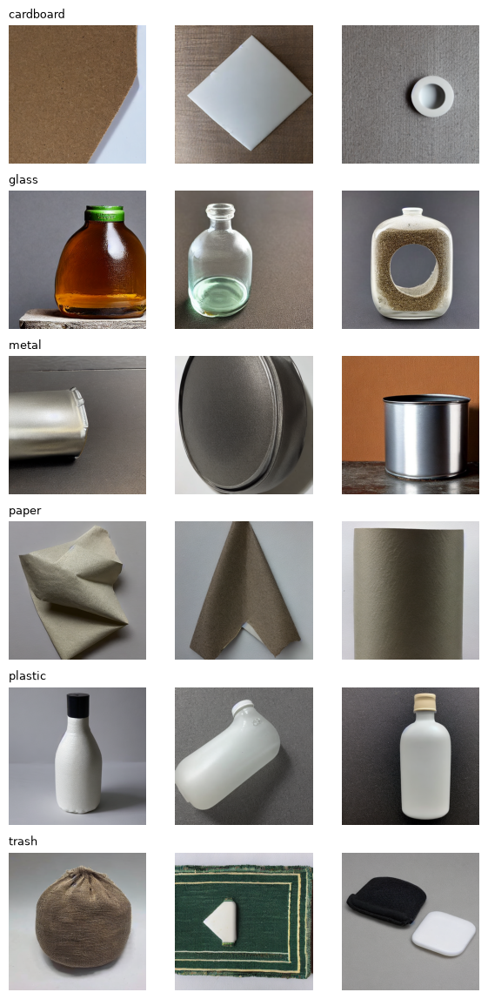

In [23]:
if RUN_LORA:  # only run if the LoRA switch is on
    # Generate synthetic images (L10)
    from diffusers import StableDiffusionPipeline  # Stable Diffusion image-generation pipeline
    import matplotlib.pyplot as plt  # matplotlib for the preview chart

    dtype = torch.float16  # use 16-bit numbers to save GPU memory
    pipe = StableDiffusionPipeline.from_pretrained(  # load the base Stable Diffusion model ...
        "stable-diffusion-v1-5/stable-diffusion-v1-5",
        torch_dtype=dtype, safety_checker=None, requires_safety_checker=False).to("cuda")  # ... in half precision, safety checker off, and move it to the GPU

    ADAPTER_NAME, LORA_SCALE = "ecosort_adapter", 0.85  # name of our LoRA adapter and how strongly to apply it (0.85)
    try: pipe.unload_lora_weights()  # remove any LoRA already loaded ...
    except Exception: pass  # ... ignore the error if none was loaded
    pipe.load_lora_weights(str(LORA_TENSORS / "ecosort_lora.safetensors"), adapter_name=ADAPTER_NAME)  # load our trained LoRA weights
    pipe.set_adapters([ADAPTER_NAME], adapter_weights=[LORA_SCALE])  # activate the adapter at the chosen strength
    print(f"✅ LoRA active (scale={LORA_SCALE})")  # confirm the LoRA is active

    PROMPT = ("a ecosort studio product photo of one {item}, full object visible, "  # prompt template; {item} is replaced by the class phrase
              "centered on a plain white background, sharp focus, realistic photography")
    NEGATIVE = ("multiple items, clutter, busy background, text, logo, watermark, hands, people, room, "  # things the model should avoid
                "outdoors, cartoon, illustration, CGI, low quality, blurry, distorted, stretched, partial, cropped")
    gen_params = {"num_inference_steps": 25, "guidance_scale": 7.0, "height": 512, "width": 512}  # generation settings: 25 steps, guidance 7.0, 512x512 image
    BASE_SEEDS = {c: 42 + i for i, c in enumerate(CATEGORIES)}  # different fixed seed for each class so results can be repeated

    for cls_name in CATEGORIES:  # for each class ...
        d = GEN_DIR / cls_name  # folder for this class's generated images
        if d.exists(): shutil.rmtree(d)  # delete old images in it
        d.mkdir(parents=True)  # create the folder
        for i in range(IMAGES_PER_CLASS):  # generate the required number of images
            g = torch.Generator(device="cuda").manual_seed(BASE_SEEDS[cls_name] * 100 + i)  # random generator with a fixed seed, so each image is repeatable
            im = pipe(prompt=PROMPT.format(item=phrase(cls_name)), negative_prompt=NEGATIVE, generator=g, **gen_params).images[0]  # generate one image from the prompt (with the negative prompt and settings)
            im.save(d / f"{cls_name}_gen_{i+1:02d}.png")  # save it as e.g. glass_gen_01.png
        print(f"✅ {cls_name}: {IMAGES_PER_CLASS} images")  # print that this class is done

    # Preview grid + reproducibility record (for the report)
    fig, axes = plt.subplots(len(CATEGORIES), 3, figsize=(7, 2.4 * len(CATEGORIES)))  # preview figure: one row per class, 3 images each
    for r, cls_name in enumerate(CATEGORIES):  # for each class ...
        for c, fp in enumerate(sorted((GEN_DIR / cls_name).iterdir())[:3]):  # ...and its first 3 images
            axes[r][c].imshow(Image.open(fp)); axes[r][c].axis("off")  # show the image without axes
        axes[r][0].set_title(cls_name, fontsize=9, loc="left")  # label the row with the class name
    plt.savefig(FINAL_DIR / "generated_preview.png", dpi=150, bbox_inches="tight"); plt.show()  # save the preview PNG and show it
    with open(FINAL_DIR / "generation_settings.json", "w") as f:  # save the generation settings as JSON for the report
        json.dump({"base_model": "stable-diffusion-v1-5", "lora_scale": LORA_SCALE, "seeds": BASE_SEEDS,
                   "prompt_template": PROMPT, "negative_prompt": NEGATIVE, **gen_params}, f, indent=2)

    # Free GPU memory
    del pipe; gc.collect(); torch.cuda.empty_cache()  # free GPU memory
else:  # otherwise (LoRA off):
    print('⏭️ Skipped (LoRA steps are off or no GPU found).')  # tell the user this step was skipped

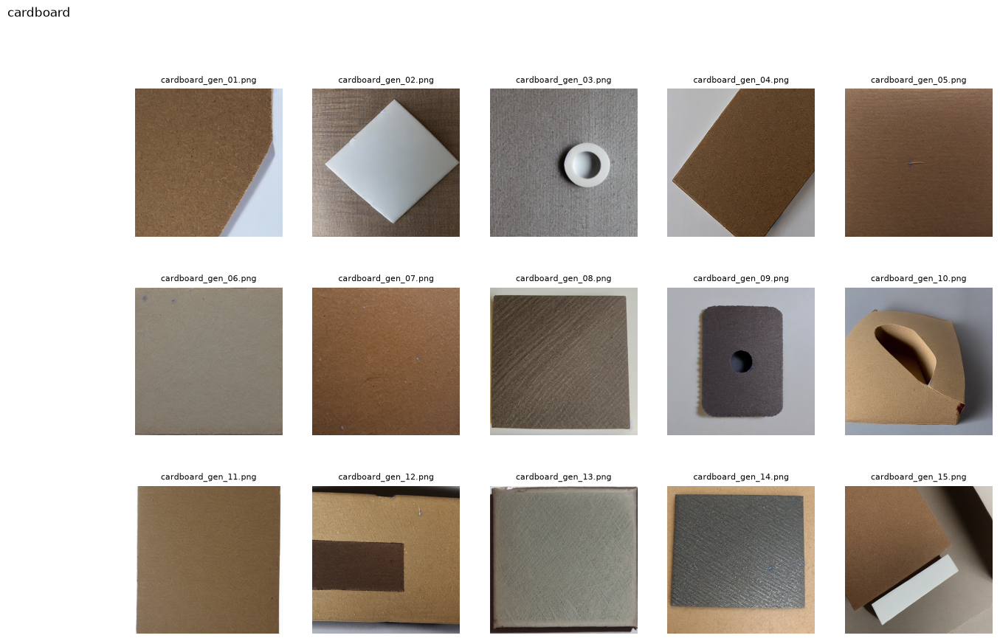

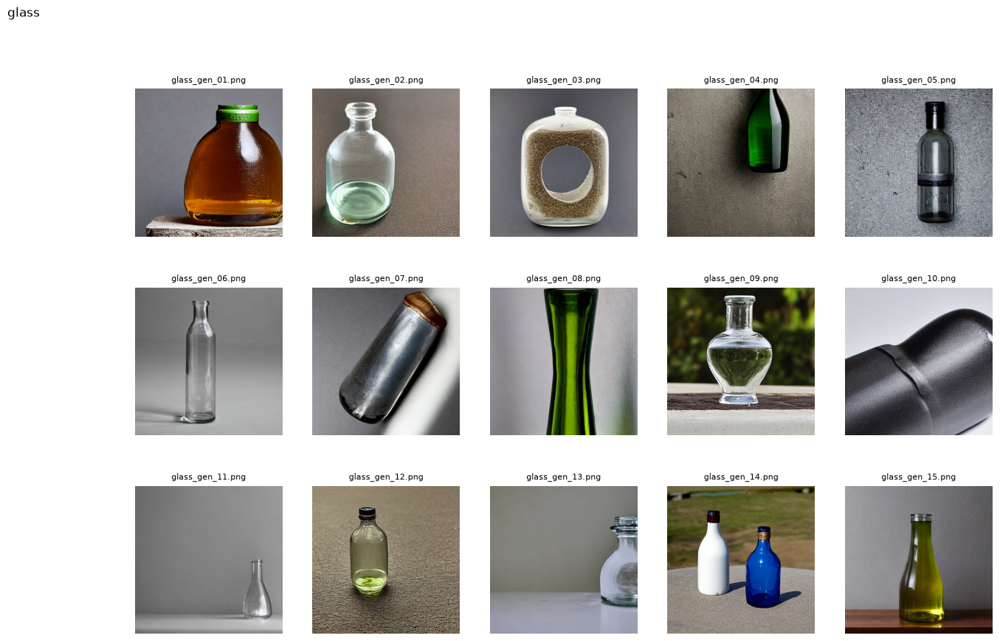

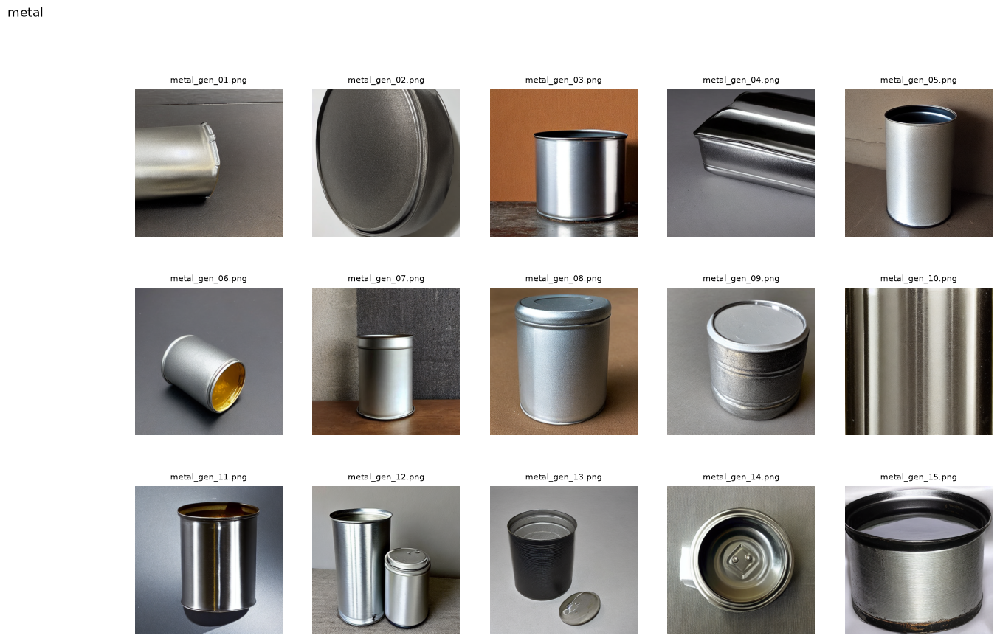

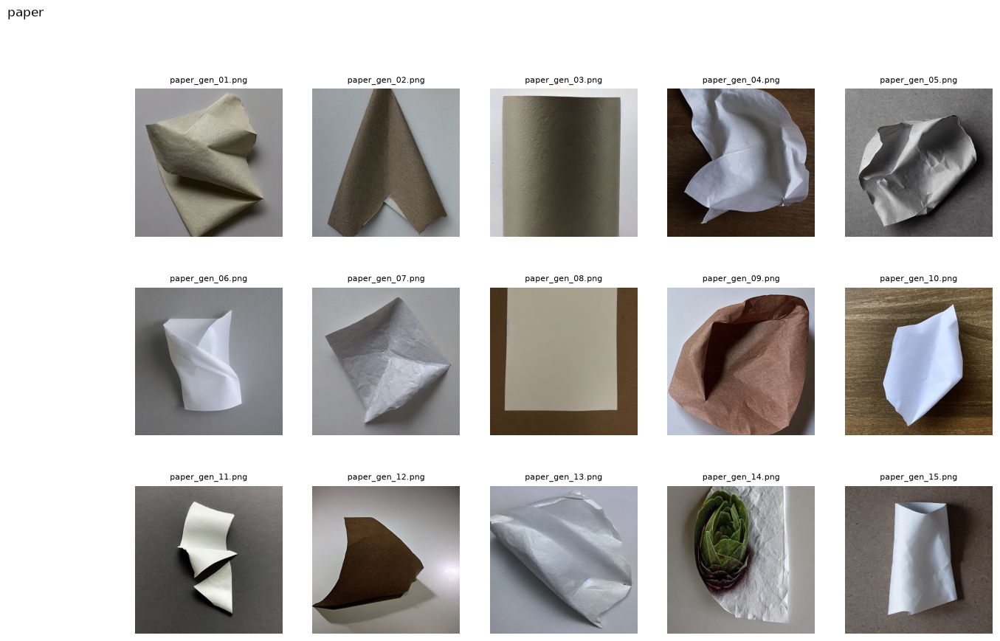

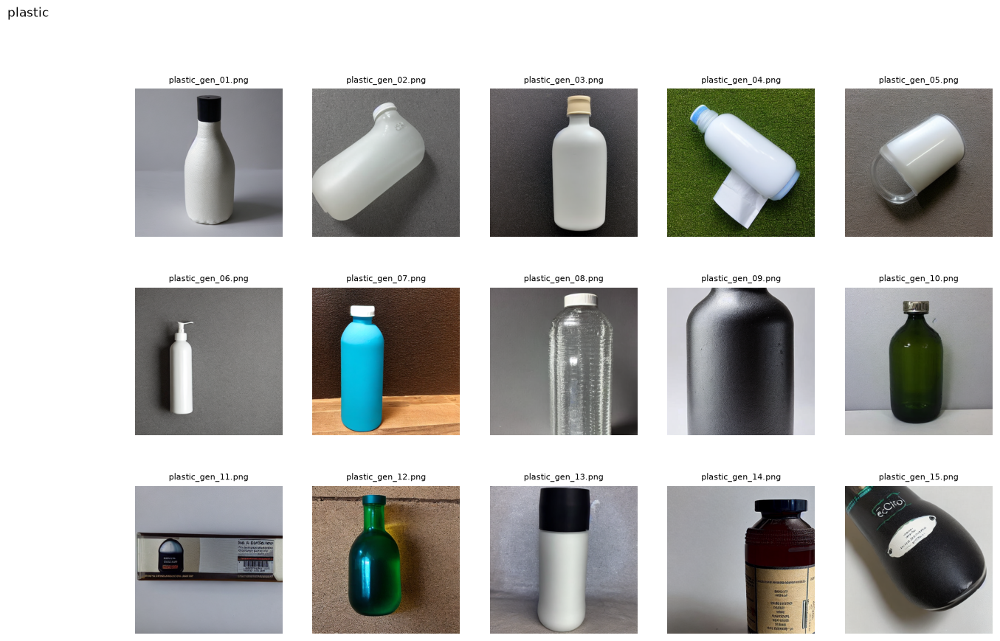

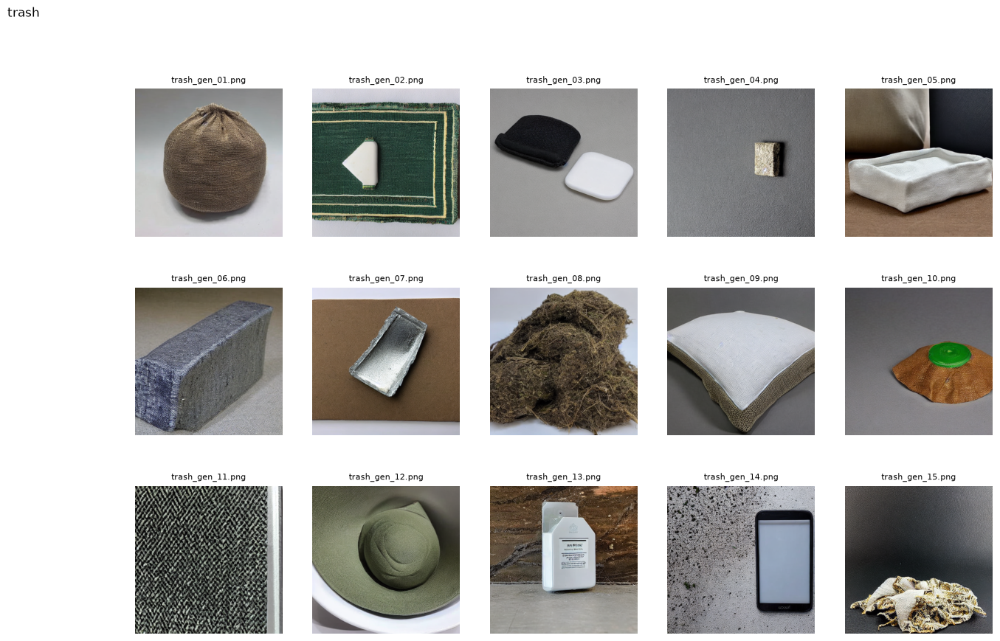

In [24]:
# ===== Curation: view all generated images per class =====
import math  # math for rounding up the number of rows
import matplotlib.pyplot as plt  # matplotlib for plotting

def show_class(cls_name, cols=5):  # show all generated images of one class in a grid
    files = sorted((GEN_DIR / cls_name).glob("*.png"))  # list the generated PNG files
    rows = max(1, math.ceil(len(files) / cols))  # number of rows needed for the grid
    fig, axes = plt.subplots(rows, cols, figsize=(3 * cols, 3.3 * rows))  # create the grid of plots
    axes = np.array(axes).reshape(-1)  # flatten the grid into a simple list
    for ax in axes: ax.axis("off")  # hide all axes first
    for ax, fp in zip(axes, files):  # draw each image with its file name as the title
        ax.imshow(Image.open(fp)); ax.set_title(fp.name, fontsize=8)
    fig.suptitle(cls_name, fontsize=12, x=0.01, ha="left")  # class name as the figure title
    plt.show()  # display the figure

for c in CATEGORIES:  # do this for every class
    show_class(c)  # so you can inspect each class and decide which to reject

In [25]:
# ===== Curation: reject by filename, keep a record =====
#REJECT = []   # e.g. ["cardboard_gen_01.png", "paper_gen_03.png"]
REJECT = [  # list of generated images to reject (file names, chosen by looking at the images)
    # cardboard (keep 5: 01, 04, 05, 07, 11)
    "cardboard_gen_02.png",  # white plastic shape on top
    "cardboard_gen_03.png",  # grey ribbed surface with white ring
    "cardboard_gen_06.png",  # grey-beige flat board, unclear material
    "cardboard_gen_08.png",  # grey-brown ribbed square, not clearly cardboard
    "cardboard_gen_09.png",  # grey square with hole
    "cardboard_gen_10.png",  # odd curved piece with hole
    "cardboard_gen_12.png",  # dark rectangle strip, unclear object
    "cardboard_gen_13.png",  # grey tile-like square
    "cardboard_gen_14.png",  # grey felt-like sheet
    "cardboard_gen_15.png",  # extra white strip

    # glass (keep 8: 01, 02, 05, 06, 09, 11, 12, 15)
    "glass_gen_03.png",      # ceramic-looking jar with hole
    "glass_gen_04.png",      # bottle cropped at the top edge
    "glass_gen_07.png",      # grey metal-looking cylinder
    "glass_gen_08.png",      # green neck only, cropped
    "glass_gen_10.png",      # black cylinder close-up
    "glass_gen_13.png",      # jar cut off at the edge of the image
    "glass_gen_14.png",      # opaque white bottle next to a blue one

    # metal (keep 9: 03, 05, 06, 07, 08, 09, 11, 12, 13)
    "metal_gen_01.png",      # cropped cylinder on its side
    "metal_gen_02.png",      # extreme close-up of a lid
    "metal_gen_04.png",      # cropped metallic shape, unclear object
    "metal_gen_10.png",      # close-up cylinder, no context
    "metal_gen_14.png",      # top-down view, odd handle, unclear object
    "metal_gen_15.png",      # cropped cylinder

    # paper (keep 8: 01, 04, 05, 06, 07, 08, 09, 10)
    "paper_gen_02.png",      # brown V-shaped cut-out
    "paper_gen_03.png",      # roll / tube shape
    "paper_gen_11.png",      # white curled strips, unclear
    "paper_gen_12.png",      # brown cone shape
    "paper_gen_13.png",      # foil-like silver sheet
    "paper_gen_14.png",      # plant leaves on paper
    "paper_gen_15.png",      # tube / roll shape

    # plastic (keep 7: 01, 02, 03, 06, 07, 08, 13)
    "plastic_gen_04.png",    # bottle on grass with extra paper
    "plastic_gen_05.png",    # odd cup shape with handle
    "plastic_gen_09.png",    # matte black bottle, cropped, looks like metal
    "plastic_gen_10.png",    # dark green glass-looking bottle with metal cap
    "plastic_gen_11.png",    # sideways bottle, label dominates
    "plastic_gen_12.png",    # teal glass-looking bottle
    "plastic_gen_14.png",    # brown glass-style bottle
    "plastic_gen_15.png",    # cropped dark bottle with label

    # trash (keep 4: 05, 07, 08, 15)
    "trash_gen_01.png",      # sack, unrecognisable
    "trash_gen_02.png",      # patterned mat with white blob
    "trash_gen_03.png",      # black and white pads, unclear
    "trash_gen_04.png",      # tiny stone-like object
    "trash_gen_06.png",      # grey slab, unclear
    "trash_gen_09.png",      # cushion
    "trash_gen_10.png",      # brass piece with green cap, looks like metal
    "trash_gen_11.png",      # fabric texture close-up
    "trash_gen_12.png",      # green bowl-like shape
    "trash_gen_13.png",      # white device on a wall
    "trash_gen_14.png",      # phone on a speckled floor
]

REJECT_DIR = LORA_DIR / "generated_rejected"  # folder where rejected images are moved (kept, not deleted)
REJECT_DIR.mkdir(exist_ok=True)  # create it if needed

generated = {c: len(list((GEN_DIR / c).glob("*.png"))) + len(list((REJECT_DIR / c).glob("*.png"))) for c in CATEGORIES}  # generated = still here + already rejected, so re-running this cell gives the same table
moved = {c: len(list((REJECT_DIR / c).glob("*.png"))) for c in CATEGORIES}  # rejected so far (includes earlier runs)
for name in REJECT:  # go through every rejected file name
    cls_name = name.split("_gen_")[0]  # class name is the part before '_gen_'
    src = GEN_DIR / cls_name / name  # where that image currently is
    if src.exists():  # only move it if the file exists
        (REJECT_DIR / cls_name).mkdir(exist_ok=True)  # make a folder for the class inside the rejected folder
        shutil.move(str(src), str(REJECT_DIR / cls_name / name)); moved[cls_name] += 1  # move the file there and count it
    else:  # otherwise ...
        print("⚠️ not found:", name)  # warn about a file name that was not found (typo or a different run)

summary = pd.DataFrame({"generated": generated, "rejected": moved})  # table: generated vs rejected per class
summary["kept"] = summary["generated"] - summary["rejected"]  # kept = generated - rejected
summary.loc["TOTAL"] = summary.sum()  # add a TOTAL row
display(summary)  # show the table
summary.to_csv(FINAL_DIR / "curation_summary.csv")  # save it as a CSV for the report
if not REJECT: print("⚠️ REJECT is empty: nothing was removed yet.")  # warn if nothing was rejected

,generated,rejected,kept
cardboard,15,10,5
glass,15,7,8
metal,15,6,9
paper,15,7,8
plastic,15,8,7
trash,15,11,4
TOTAL,90,49,41


### ✋ Manual curation (do this now, then run the next cell)
Look at the grids above and list every image that does **not** clearly show the right item in the `REJECT` list in the next cell (file names such as `"glass_gen_03.png"`). The cell moves those files into `EcoSort_Files/lora/generated_rejected/` (they are kept, not deleted) and prints a generated / rejected / kept table.

trash: 100%|██████████| 4/4 [00:00<00:00, 30.37it/s]


✅ Processed 41 images | white-background check passed: 0/41


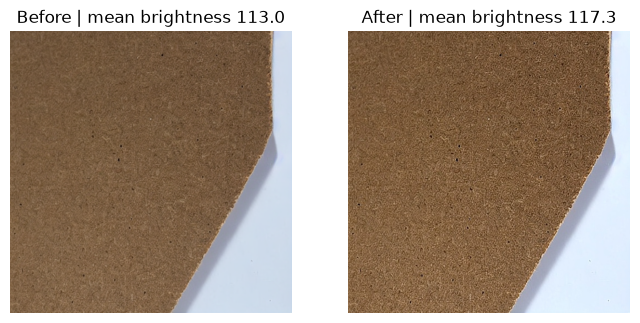

In [26]:
if RUN_LORA:  # only run if the LoRA switch is on
    # Process and validate generated images (L11)
    from datetime import datetime  # date and time, for the processing log
    from PIL import ImageEnhance, ImageFilter, ImageOps  # Pillow tools: adjust brightness/contrast/sharpness, filters, rotate by EXIF
    from tqdm import tqdm  # tqdm shows a progress bar
    import matplotlib.pyplot as plt  # matplotlib for the before/after chart

    TARGET_SIZE = (512, 512)  # final image size 512x512
    BRIGHTNESS_FACTOR, CONTRAST_FACTOR, SHARPNESS_FACTOR = 1.05, 1.10, 1.10  # small boosts to brightness (+5%), contrast (+10%) and sharpness (+10%)
    UNSHARP_RADIUS, UNSHARP_PERCENT, UNSHARP_THRESHOLD = 1, 120, 3  # unsharp mask settings (radius, strength, threshold)
    WHITE_THRESHOLD, MAX_CHANNEL_SPREAD, JPEG_QUALITY = 240, 15, 95  # limits for the 'is the background white' check, and JPEG quality 95

    def corner_is_white(img, patch=24):  # check whether the image corners are white (plain background)
        a = np.array(img); h, w = a.shape[:2]  # convert the image to a NumPy array and get its height and width
        corners = [a[:patch, :patch], a[:patch, w-patch:], a[h-patch:, :patch], a[h-patch:, w-patch:]]  # cut out four 24x24 pixel corner patches
        ok = 0  # count of white corners
        for c in corners:  # go through each corner
            px = c.reshape(-1, 3)  # flatten the patch to a list of RGB pixels
            white = (px.min(axis=1) >= WHITE_THRESHOLD) & ((px.max(axis=1) - px.min(axis=1)) <= MAX_CHANNEL_SPREAD)  # pixel is white if all channels >= 240 and the channels are similar (not coloured)
            ok += white.mean() > 0.9  # count the corner as white if more than 90% of its pixels are white
        return ok >= 3  # the image has a white background if at least 3 corners are white

    def process_image(in_path, out_path):  # clean up one generated image and save it
        with Image.open(in_path) as s:  # open the file (closed automatically afterwards)
            img = ImageOps.exif_transpose(s).convert("RGB")  # fix rotation from EXIF data and make sure it is RGB
        if img.size != TARGET_SIZE:  # resize to 512x512 only if needed (high-quality LANCZOS)
            img = img.resize(TARGET_SIZE, Image.Resampling.LANCZOS)
        img = ImageEnhance.Brightness(img).enhance(BRIGHTNESS_FACTOR)  # increase brightness slightly
        img = ImageEnhance.Contrast(img).enhance(CONTRAST_FACTOR)  # increase contrast slightly
        img = ImageEnhance.Sharpness(img).enhance(SHARPNESS_FACTOR)  # increase sharpness slightly
        img = img.filter(ImageFilter.UnsharpMask(UNSHARP_RADIUS, UNSHARP_PERCENT, UNSHARP_THRESHOLD))  # apply an unsharp mask to make edges crisper
        img.save(out_path, "JPEG", quality=JPEG_QUALITY)  # save as a high-quality JPEG
        return {"size": img.size, "white_bg": bool(corner_is_white(img)),  # return facts about the result for the log: image size and whether the background is white
                "mean_brightness": round(float(np.array(img).mean()), 1)}  # and the average brightness

    proc_log = []  # list that will hold one log entry per image
    for cls_name in CATEGORIES:  # for each class ...
        in_dir, out_dir = GEN_DIR / cls_name, PROC_DIR / cls_name  # input folder (generated) and output folder (processed)
        if out_dir.exists(): shutil.rmtree(out_dir)  # delete old processed images
        out_dir.mkdir(parents=True)  # create the output folder
        for fp in tqdm(sorted(p for p in in_dir.iterdir() if p.suffix.lower() in IMG_EXTS), desc=cls_name):  # process each image with a progress bar
            proc_log.append({"class": cls_name, "file": fp.stem + ".jpg", **process_image(fp, out_dir / (fp.stem + ".jpg"))})  # process it and add its details to the log
    with open(PROC_DIR / "processing_log.json", "w") as f:  # save the log as JSON
        json.dump({"time": datetime.now().isoformat(timespec="seconds"), "images": proc_log}, f, indent=2)  # with the time of processing and every image's entry
    print(f"✅ Processed {len(proc_log)} images | white-background check passed: {sum(r['white_bg'] for r in proc_log)}/{len(proc_log)}")  # print how many images were processed and how many passed the white-background check

    # Before vs After
    cls_name = CATEGORIES[0]                      # change to show another class
    fp = sorted((GEN_DIR / cls_name).iterdir())[0]  # take the first image of the first class (CATEGORIES[0]) as an example
    before = Image.open(fp).convert("RGB"); after = Image.open(PROC_DIR / cls_name / (fp.stem + ".jpg"))  # load the original (before) and the processed (after) version
    fig, ax = plt.subplots(1, 2, figsize=(8, 4))  # create two side-by-side plots
    for a, im, t in zip(ax, [before, after], ["Before", "After"]):  # loop over the before and after images
        a.imshow(im); a.set_title(f"{t} | mean brightness {np.array(im).mean():.1f}"); a.axis("off")  # show the image with its mean brightness
    plt.savefig(FINAL_DIR / "before_after.png", dpi=150, bbox_inches="tight"); plt.show()  # save the before/after chart and show it
else:  # otherwise (LoRA off):
    print('⏭️ Skipped (LoRA steps are off or no GPU found).')  # tell the user this step was skipped

## Part 4: Experiment C: add the processed synthetic images to training (L3 method)
Synthetic images go into TRAIN only; validation stays 100% real. Skipped if no synthetic images exist.

In [27]:
SYN_DIR = BASE_DIR / "lora" / "processed_images"  # folder with the processed synthetic images
AUG_DIR = BASE_DIR / "dataset_aug"  # folder for the new combined dataset (real + synthetic)
HAVE_SYN = SYN_DIR.exists() and any(SYN_DIR.rglob("*.jpg"))  # True if synthetic images exist
print("Synthetic images available:", HAVE_SYN)  # print whether synthetic images were found
if HAVE_SYN:  # only continue if they exist
    if AUG_DIR.exists(): shutil.rmtree(AUG_DIR)  # delete any old combined dataset
    shutil.copytree(DATA_DIR, AUG_DIR)  # copy the original train/val split into the new folder
    added = 0  # counter for added images
    for cls_dir in SYN_DIR.iterdir():  # go through each synthetic class folder
        if cls_dir.is_dir() and (AUG_DIR / "train" / cls_dir.name).exists():  # only use classes that exist in the training set
            for f in cls_dir.glob("*.jpg"):  # for each synthetic image ...
                shutil.copy(f, AUG_DIR / "train" / cls_dir.name / f"syn_{f.name}"); added += 1  # copy it into that class's training folder with a 'syn_' prefix and count it
    print(f"✅ Added {added} synthetic images to the training set (validation unchanged)")  # print how many were added (validation set stays untouched so results are fair)

Synthetic images available: True
✅ Added 41 synthetic images to the training set (validation unchanged)


In [28]:
if HAVE_SYN:  # only run if synthetic images exist
    # Cell 15: Experiment C - same fine-tuning as B, with synthetic data
    train_ds_aug = datasets.ImageFolder(AUG_DIR / "train", transform=train_tfms)  # load the combined training set (real + synthetic) with augmentation
    assert train_ds_aug.classes == train_ds.classes, "Class order mismatch"  # check the class order is the same as before
    train_dl = DataLoader(train_ds_aug, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)  # rebinds global used by train_model

    torch.manual_seed(SEED)  # same random seed as A and B for a fair comparison
    model_c = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)  # fresh pre-trained ResNet18
    model_c.fc = nn.Linear(model_c.fc.in_features, num_classes)  # new 6-class output layer
    for p in model_c.parameters(): p.requires_grad = False  # freeze all layers ...
    for p in model_c.layer4.parameters(): p.requires_grad = True  # ... unfreeze layer4 ...
    for p in model_c.fc.parameters(): p.requires_grad = True  # ... and the new last layer (same as experiment B)
    model_c = model_c.to(DEVICE)  # move to the device
    optimizer_c = optim.Adam([  # Adam with two learning rates:
        {"params": model_c.layer4.parameters(), "lr": 3e-4},  # layer4 = 0.0003
        {"params": model_c.fc.parameters(),     "lr": 1e-3},  # last layer = 0.001
    ])
    frozen_c = [model_c.conv1, model_c.bn1, model_c.layer1, model_c.layer2, model_c.layer3]  # early layers that stay frozen
    best_path_c = ARTIFACTS / "expC_best.pth"  # file name for the best Experiment C model
    hist_c, best_acc_c = train_model(model_c, optimizer_c, criterion, best_path_c,  # train on real + synthetic images and save the best version
                                     tag="C-FineTune+Synthetic", bn_eval_modules=frozen_c)
    print(f"\n🏁 Experiment C best val acc: {best_acc_c:.3f}")  # print the best validation accuracy
else:  # otherwise (no synthetic images):
    print('⏭️ Skipped (LoRA steps are off or no GPU found).')  # tell the user this step was skipped

[C-FineTune+Synthetic] Epoch 1/5 | train_acc=0.751 val_acc=0.817 | train_loss=0.678 val_loss=0.509
   💾 Saved best model (0.817) -> expC_best.pth
[C-FineTune+Synthetic] Epoch 2/5 | train_acc=0.894 val_acc=0.865 | train_loss=0.310 val_loss=0.455
   💾 Saved best model (0.865) -> expC_best.pth
[C-FineTune+Synthetic] Epoch 3/5 | train_acc=0.942 val_acc=0.853 | train_loss=0.177 val_loss=0.563
[C-FineTune+Synthetic] Epoch 4/5 | train_acc=0.945 val_acc=0.865 | train_loss=0.169 val_loss=0.476
[C-FineTune+Synthetic] Epoch 5/5 | train_acc=0.948 val_acc=0.897 | train_loss=0.145 val_loss=0.369
   💾 Saved best model (0.897) -> expC_best.pth

🏁 Experiment C best val acc: 0.897


In [29]:
# Final comparison table (A vs B, plus C if it was run)
rows = [("A - Feature extraction", len(train_ds), best_acc_fe), ("B - Fine-tuning", len(train_ds), best_acc_ft)]  # rows for the final table: number of training images and best accuracy per experiment
if HAVE_SYN:  # only if Experiment C was run ...
    rows.append(("C - Fine-tuning + synthetic", len(train_ds_aug), best_acc_c))  # ... add it to the table
final = pd.DataFrame(rows, columns=["Experiment", "Train images", "Best val accuracy"]).round(3)  # build the DataFrame, rounded to 3 decimals
display(final)  # show the table
final.to_csv(ARTIFACTS / "final_comparison.csv", index=False)  # save it as a CSV for the report

,Experiment,Train images,Best val accuracy
0,A - Feature extraction,2024,0.817
1,B - Fine-tuning,2024,0.887
2,C - Fine-tuning + synthetic,2065,0.897


## Part 5: Task 2 testing evidence (L7, L8)
Checks consistency, "Unsure" behaviour and real-world robustness. Everything loads from disk, so this part works even after restarting the kernel.
Outputs are saved to `EcoSort_Files/task2_evidence/` .
**Before 5.6:** put web or phone photos in `EcoSort_Files/phone_photos/`, named with the true class first (e.g. `plastic_01.jpg`).

In [30]:
# 5.1 Setup: load the best checkpoint (A, B or C) from disk
EVID      = BASE_DIR / "task2_evidence"; EVID.mkdir(parents=True, exist_ok=True)  # folder for saved test evidence; create it if missing
PHONE_DIR = BASE_DIR / "phone_photos";   PHONE_DIR.mkdir(parents=True, exist_ok=True)  # folder for your own phone/web photos; create it if missing
VAL_DIR   = BASE_DIR / "dataset" / "val"  # validation images folder
CONF_THRESHOLD = 0.60                    # same value as the app

from PIL import ImageOps  # ImageOps.exif_transpose rotates phone photos upright
eval_tfm = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224), transforms.ToTensor(),  # preprocessing for evaluation (same as the app)
                               transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

best_ckpt, best_val = None, -1.0  # no best checkpoint found yet; start below any real accuracy
for nm in ["expA_best.pth", "expB_best.pth", "expC_best.pth"]:  # check each experiment's saved model
    pth = ARTIFACTS / nm  # path of the checkpoint file
    if pth.exists():  # only if the file exists
        va = torch.load(pth, map_location="cpu").get("val_acc", 0.0)  # read its saved validation accuracy
        if va > best_val: best_ckpt, best_val = pth, va  # remember the checkpoint with the highest accuracy
assert best_ckpt is not None, "No checkpoint found in EcoSort_Files/artifacts"  # stop if no checkpoint was found
# Evidence must match the deployed model (the app also picks the highest val_acc checkpoint).
if RUN_LORA and HAVE_SYN and best_ckpt.name != "expC_best.pth":  # warn if C was trained but another model is better
    print("⚠️ Experiment C exists but is not the best checkpoint. The app and this evidence both use", best_ckpt.name)  # tell the user which model the app and this evidence use
if "HAVE_SYN" in globals() and HAVE_SYN and not (ARTIFACTS / "expC_best.pth").exists():  # safety check: Part 4 must run before Part 5 when synthetic images exist
    raise RuntimeError("Run Part 4 (Experiment C) before Part 5, otherwise this evidence is for the wrong model.")  # stop with a clear message otherwise
ck = torch.load(best_ckpt, map_location="cpu")  # load the chosen checkpoint
CLS = ck["classes"]  # class names saved with the model
eager_m = models.resnet18(weights=None); eager_m.fc = nn.Linear(eager_m.fc.in_features, len(CLS))  # create an empty ResNet18 with the 6-class output layer
eager_m.load_state_dict(ck["state_dict"]); eager_m.eval()  # load the trained weights and set evaluation mode
print("Using checkpoint:", best_ckpt.name, "| val_acc:", round(best_val, 3), "| classes:", CLS)  # print which checkpoint is used

@torch.no_grad()  # no gradients needed
def probs_of(m, pil_img):  # function: probabilities for every class for one image
    return torch.softmax(m(eval_tfm(ImageOps.exif_transpose(pil_img).convert("RGB")).unsqueeze(0)), dim=1)[0].numpy()  # fix EXIF rotation, preprocess, run the model, softmax to probabilities, convert to NumPy
def label_of(p): return CLS[int(p.argmax())], float(p.max())  # function: the top class name and its confidence

samples = {c: sorted(f for f in (VAL_DIR / c).iterdir() if f.suffix.lower() in IMG_EXTS)[0] for c in CLS}  # one example validation image for every class

Using checkpoint: expC_best.pth | val_acc: 0.897 | classes: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


### 5.2 Re-export TorchScript from the current checkpoint and verify it matches
This overwrites `ecosort_resnet18_ts.pt` (first exported from Experiment B in Part 2) with one exported from the checkpoint chosen above, so the app loads a matching TorchScript model.


In [31]:
ts_m = torch.jit.trace(eager_m, torch.randn(1, 3, 224, 224))  # TorchScript version of the chosen model (traced with a dummy image)
ts_m.save(str(ARTIFACTS / "ecosort_resnet18_ts.pt"))  # save it, so the app loads a matching file
probe = torch.randn(4, 3, 224, 224)  # random test input of 4 images
with torch.no_grad():  # no gradients needed
    diff = (eager_m(probe) - ts_m(probe)).abs().max().item()  # largest difference between the original and TorchScript outputs
print("max logit difference (eager vs TorchScript):", diff)  # print the difference (should be 0 or tiny)
assert diff < 1e-3, "TorchScript still does not match the checkpoint"  # stop if they differ, because the app would use a wrong model
print("✅ TorchScript export matches the checkpoint")  # confirm that they match

max logit difference (eager vs TorchScript): 0.0
✅ TorchScript export matches the checkpoint


### 5.3 Consistency test: same image, 5 repeats (standard vs TorchScript)

In [32]:
REPEATS, rows = 5, []  # test the same image 5 times; list for the results
for cls_name, path in samples.items():  # for each class example ...
    img = Image.open(path)  # open the image
    runs = [probs_of(eager_m, img) for _ in range(REPEATS)]  # predict 5 times with the normal model
    p_ts = probs_of(ts_m, img)  # predict once with the TorchScript model
    rows.append({"true_class": cls_name, "file": path.name, "repeats": REPEATS,  # save one table row: true class, file name and number of repeats
                 "same_label_every_run": len({label_of(p)[0] for p in runs}) == 1,  # True if all 5 repeats give the same label
                 "label": label_of(runs[0])[0], "confidence": round(label_of(runs[0])[1], 4),  # label and confidence from the first run
                 "confidence_spread": float(max(p.max() for p in runs) - min(p.max() for p in runs)),  # how much the confidence changed between runs (should be 0)
                 "torchscript_same_label": label_of(p_ts)[0] == label_of(runs[0])[0],  # True if TorchScript gives the same label
                 "max_prob_diff_vs_eager": float(np.abs(p_ts - runs[0]).max())})  # largest probability difference between TorchScript and the normal model
cons = pd.DataFrame(rows); display(cons)  # make a table of the results and show it
cons.to_csv(EVID / "consistency_results.csv", index=False)  # save it as a CSV
print("✅ All repeats identical:", bool(cons["same_label_every_run"].all()) and bool((cons["confidence_spread"] == 0).all()))  # report whether all repeats were identical
print("✅ TorchScript agrees with standard model on all samples:", bool(cons["torchscript_same_label"].all()))  # report whether TorchScript agrees with the normal model

,true_class,file,repeats,same_label_every_run,label,confidence,confidence_spread,torchscript_same_label,max_prob_diff_vs_eager
0,cardboard,cardboard100.jpg,5,True,cardboard,0.9178,0.0,True,0.0
1,glass,glass101.jpg,5,True,glass,1.0000,0.0,True,0.0
2,metal,metal100.jpg,5,True,metal,1.0000,0.0,True,0.0
3,paper,paper1.jpg,5,True,paper,0.9976,0.0,True,0.0
4,plastic,plastic10.jpg,5,True,plastic,0.7422,0.0,True,0.0
5,trash,trash1.jpg,5,True,trash,0.9152,0.0,True,0.0


✅ All repeats identical: True
✅ TorchScript agrees with standard model on all samples: True


### 5.4 One example per class

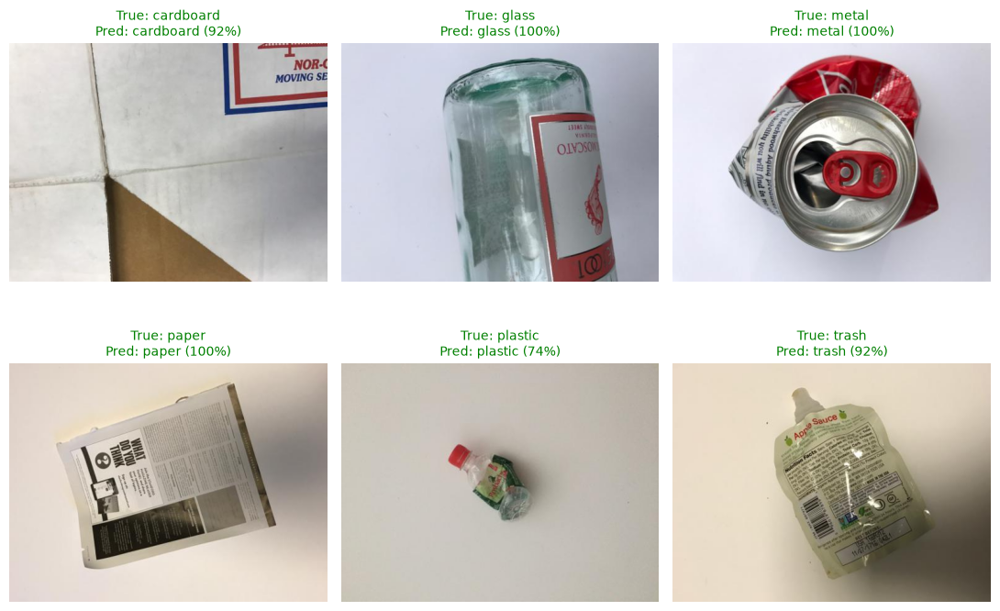

,true,pred,confidence,shown_as
0,cardboard,cardboard,0.918,cardboard
1,glass,glass,1.000,glass
2,metal,metal,1.000,metal
3,paper,paper,0.998,paper
4,plastic,plastic,0.742,plastic
5,trash,trash,0.915,trash


In [33]:
fig, axes = plt.subplots(2, 3, figsize=(11, 7.5)); ex_rows = []  # grid of 6 plots, one per class; list for the table
for ax, (cls_name, path) in zip(axes.ravel(), samples.items()):  # for each class example ...
    img = Image.open(path).convert("RGB"); p = probs_of(eager_m, img); lab, conf = label_of(p)  # open the image, predict and get label and confidence
    shown = "Unsure" if conf < CONF_THRESHOLD else lab  # what the app would show: 'Unsure' if confidence is below 0.60
    ax.imshow(img); ax.axis("off")  # show the image without axes
    ax.set_title(f"True: {cls_name}\nPred: {shown} ({conf:.0%})", fontsize=10,  # title shows true class and prediction; green if correct and confident, red otherwise
                 color=("green" if lab == cls_name and conf >= CONF_THRESHOLD else "red"))
    ex_rows.append({"true": cls_name, "pred": lab, "confidence": round(conf, 3), "shown_as": shown})  # save the row for the table
plt.tight_layout(); plt.savefig(EVID / "per_class_examples.png", dpi=150, bbox_inches="tight"); plt.show()  # save the figure and show it
pd.DataFrame(ex_rows).to_csv(EVID / "per_class_examples.csv", index=False); display(pd.DataFrame(ex_rows))  # save the table as CSV and show it

### 5.5 "Unsure" cases: lowest-confidence real images and non-waste inputs
The model has no "not waste" class, so non-waste inputs depend on the confidence threshold to be rejected.

19 of 503 validation images (3.8%) fall below the 60% threshold


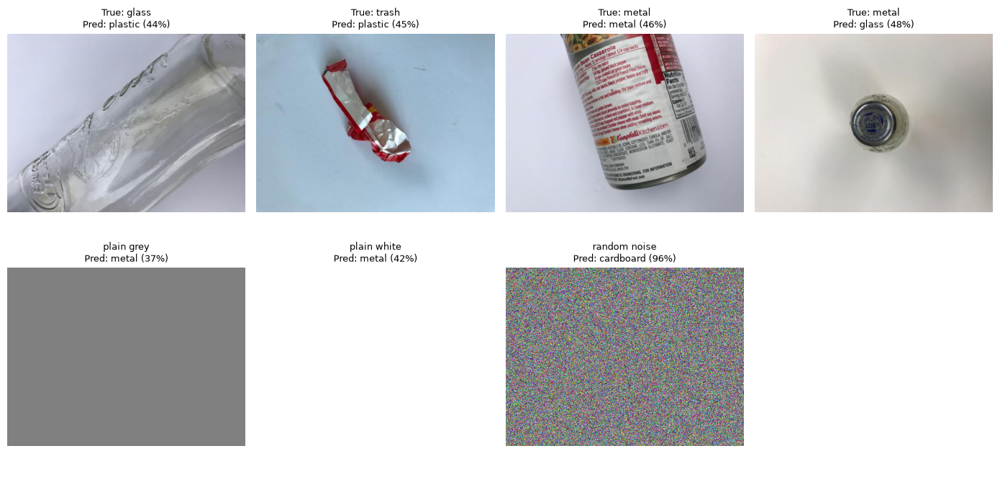

,input,type,true,pred,confidence,app_shows
0,glass139.jpg,low-confidence real,glass,plastic,0.443,Unsure
1,trash32.jpg,low-confidence real,trash,plastic,0.452,Unsure
2,metal253.jpg,low-confidence real,metal,metal,0.462,Unsure
3,metal272.jpg,low-confidence real,metal,glass,0.481,Unsure
4,trash56.jpg,low-confidence real,trash,trash,0.483,Unsure
5,plain grey,non-waste,-,metal,0.373,Unsure
6,plain white,non-waste,-,metal,0.424,Unsure
7,random noise,non-waste,-,cardboard,0.965,cardboard


In [34]:
scored = []  # list of (confidence, file, true class, predicted class)
for c in CLS:  # go through every class ...
    for f in (VAL_DIR / c).iterdir():  # ... and every validation image
        if f.suffix.lower() in IMG_EXTS:  # only image files
            lab, conf = label_of(probs_of(eager_m, Image.open(f))); scored.append((conf, f, c, lab))  # predict and store the result
scored.sort(key=lambda t: t[0]); low = scored[:5]  # sort from lowest to highest confidence and keep the 5 lowest
n_unsure = sum(1 for s in scored if s[0] < CONF_THRESHOLD)  # count how many images are below the 0.60 'Unsure' threshold
print(f"{n_unsure} of {len(scored)} validation images ({n_unsure/len(scored):.1%}) fall below the {CONF_THRESHOLD:.0%} threshold")  # print that count and percentage

rng = np.random.default_rng(42)  # random generator with a fixed seed
non_waste = {"plain grey": Image.new("RGB", (512, 384), (128, 128, 128)),  # three non-waste test images: a grey image, a white image and random noise
             "plain white": Image.new("RGB", (512, 384), (255, 255, 255)),
             "random noise": Image.fromarray(rng.integers(0, 255, (384, 512, 3), dtype=np.uint8))}
rows = []; fig, axes = plt.subplots(2, 4, figsize=(14, 7))  # table rows and a 2x4 grid of plots
for ax, (conf, f, c, lab) in zip(axes[0], low[:4]):  # loop over the 4 least confident real images
    ax.imshow(Image.open(f).convert("RGB")); ax.axis("off"); ax.set_title(f"True: {c}\nPred: {lab} ({conf:.0%})", fontsize=9)  # show the image with its true class, prediction and confidence
for conf, f, c, lab in low:  # loop over the 5 least confident images
    rows.append({"input": f.name, "type": "low-confidence real", "true": c, "pred": lab,  # add each one to the table
                 "confidence": round(conf, 3), "app_shows": "Unsure" if conf < CONF_THRESHOLD else lab})
for ax, (nm, im) in zip(axes[1], non_waste.items()):  # loop over the three non-waste images
    lab, conf = label_of(probs_of(eager_m, im)); ax.imshow(im); ax.axis("off"); ax.set_title(f"{nm}\nPred: {lab} ({conf:.0%})", fontsize=9)  # predict and plot each of them
    rows.append({"input": nm, "type": "non-waste", "true": "-", "pred": lab,  # add each one to the table
                 "confidence": round(conf, 3), "app_shows": "Unsure" if conf < CONF_THRESHOLD else lab})
axes[1][3].axis("off"); plt.tight_layout(); plt.savefig(EVID / "unsure_cases.png", dpi=150, bbox_inches="tight"); plt.show()  # hide the unused plot, save the chart and show it
unsure = pd.DataFrame(rows); display(unsure); unsure.to_csv(EVID / "unsure_cases.csv", index=False)  # build the table, show it and save it as CSV

### 5.6 Web / phone photos (real-world test)
Name each file with its true class first, e.g. `plastic_01.jpg`.

Photo accuracy: 32/77 = 41.6%


,photos,correct,unsure,avg_confidence,accuracy,wrong_but_confident
true,,,,,,
cardboard,12.0,12.0,0.0,0.969,1.000,0
glass,19.0,3.0,5.0,0.774,0.158,13
metal,19.0,10.0,1.0,0.927,0.526,8
plastic,19.0,6.0,6.0,0.788,0.316,7
trash,8.0,1.0,1.0,0.856,0.125,6
ALL,77.0,32.0,13.0,0.854,0.416,34


Wrong AND shown with confidence >= 60% (app would not say 'Unsure'): 34 of 45 wrong photos


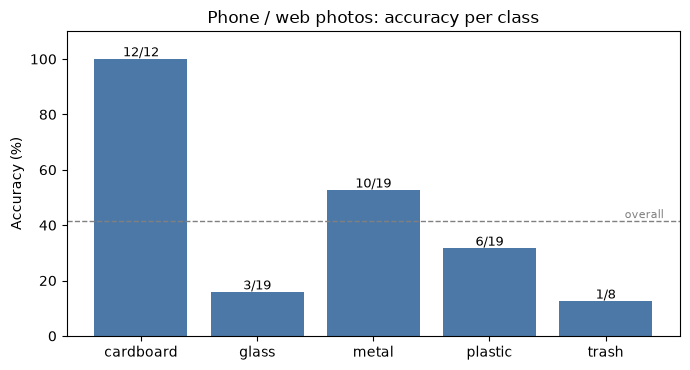

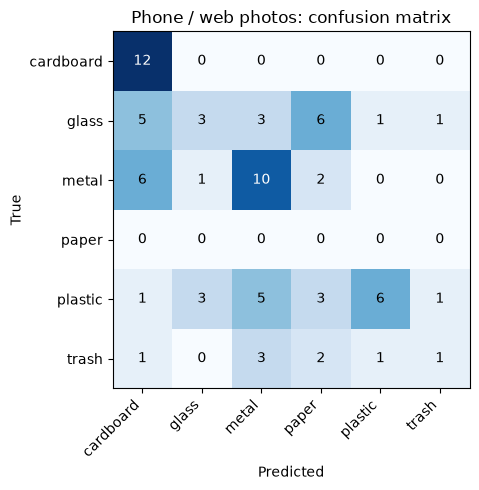

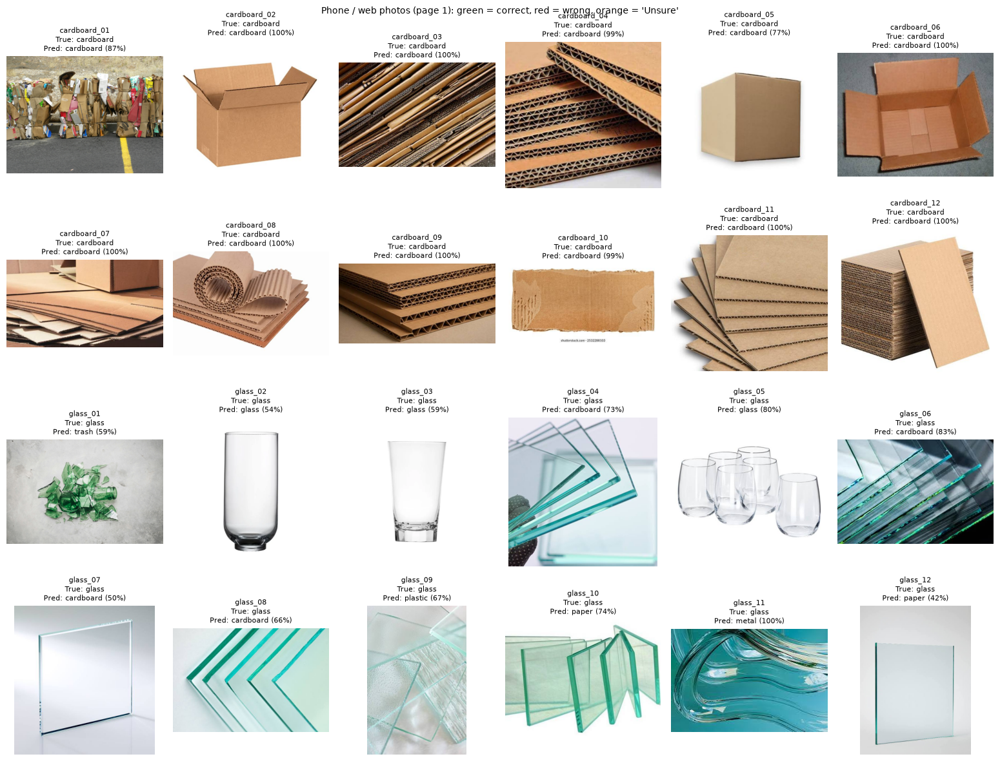

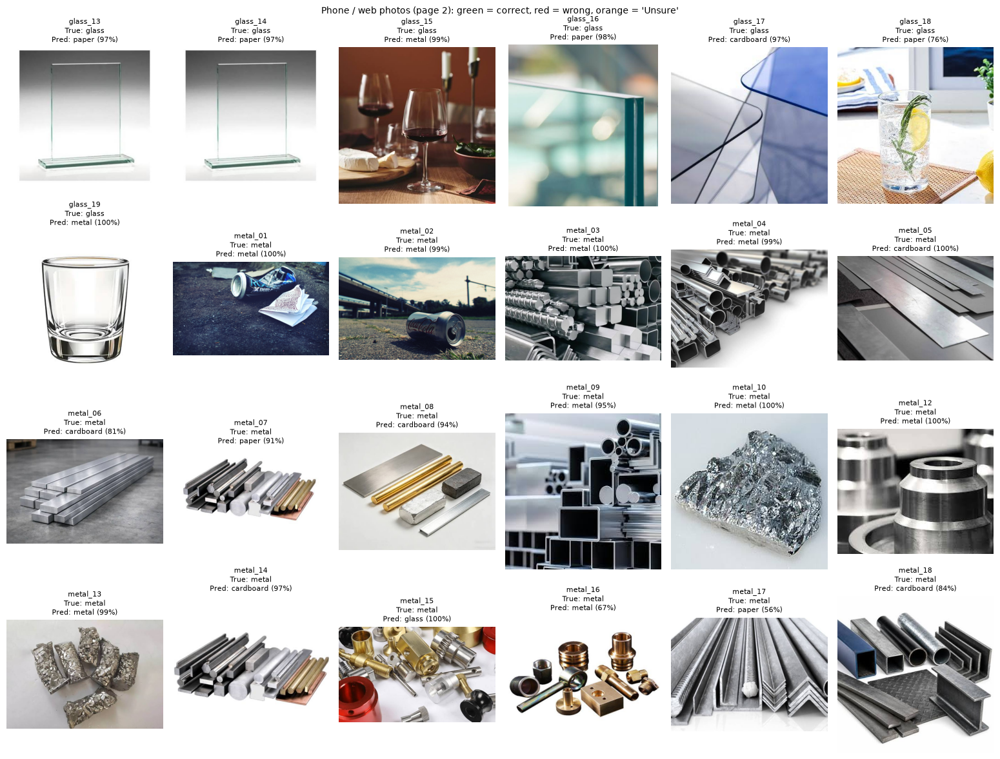

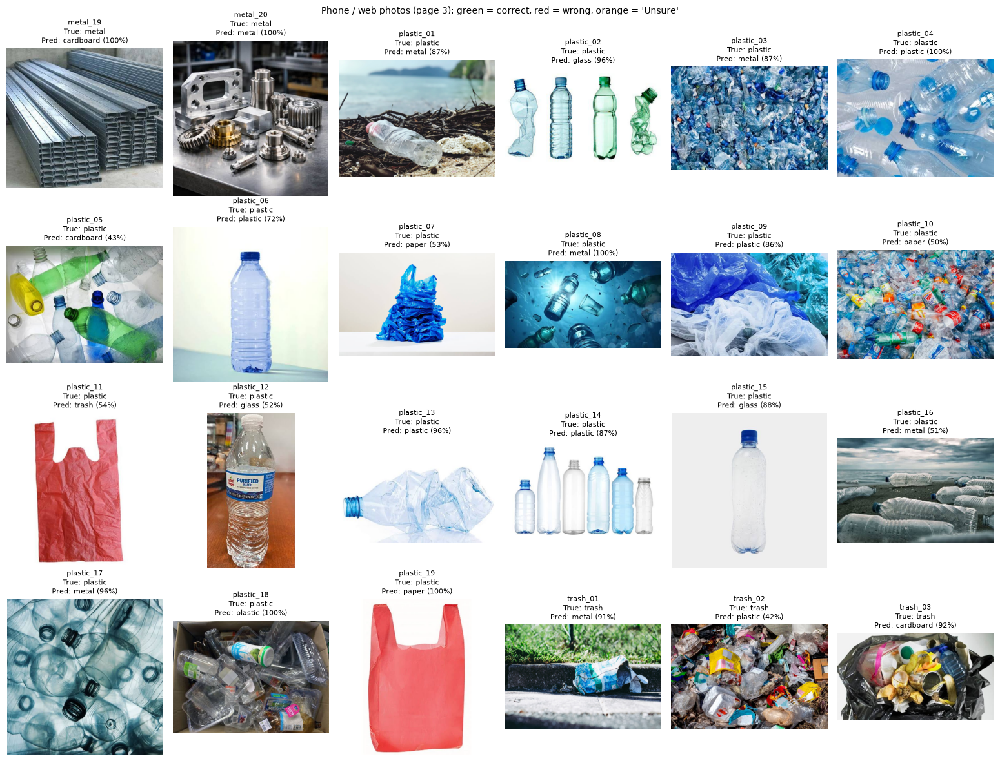

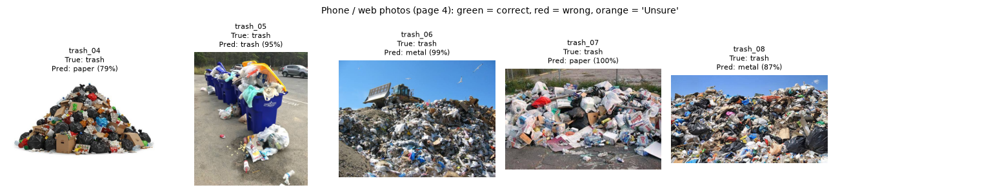

,file,true,pred,confidence,app_shows,correct,top3
0,cardboard_01.jpg,cardboard,cardboard,0.867,cardboard,True,"cardboard 87%, paper 13%, trash 0%"
1,cardboard_02.jpg,cardboard,cardboard,0.998,cardboard,True,"cardboard 100%, paper 0%, trash 0%"
2,cardboard_03.jpg,cardboard,cardboard,1.000,cardboard,True,"cardboard 100%, paper 0%, metal 0%"
3,cardboard_04.jpg,cardboard,cardboard,0.994,cardboard,True,"cardboard 99%, metal 1%, paper 0%"
4,cardboard_05.jpg,cardboard,cardboard,0.773,cardboard,True,"cardboard 77%, paper 22%, trash 0%"
...,...,...,...,...,...,...,...
72,trash_04.jpg,trash,paper,0.789,paper,False,"paper 79%, metal 16%, cardboard 4%"
73,trash_05.jpg,trash,trash,0.946,trash,True,"trash 95%, paper 4%, cardboard 2%"
74,trash_06.jpg,trash,metal,0.992,metal,False,"metal 99%, plastic 0%, glass 0%"
75,trash_07.jpg,trash,paper,0.999,paper,False,"paper 100%, cardboard 0%, metal 0%"


In [35]:
# 5.6 Web / phone photos: results table, per-class accuracy, confusion matrix, paged photo grids
import math  # math for rounding up the number of pages
files = sorted(f for f in PHONE_DIR.iterdir() if f.suffix.lower() in IMG_EXTS)  # list your phone/web photos
if not files:  # if there are none ...
    print(f"No photos yet. Add some to {PHONE_DIR} (e.g. plastic_01.jpg) and re-run this cell.")  # tell the user where to put them
else:  # otherwise ...
    rows = []  # list for results
    for f in files:  # go through every photo
        true = f.stem.split("_")[0].lower(); p = probs_of(eager_m, Image.open(f)); lab, conf = label_of(p)  # true class = the file name before '_' (e.g. glass_01.jpg -> glass); predict and get label and confidence
        rows.append({"file": f.name, "true": true if true in CLS else "?", "pred": lab, "confidence": round(conf, 3),  # one row of results: file, true class, prediction and confidence
                     "app_shows": "Unsure" if conf < CONF_THRESHOLD else lab,  # what the app would show (Unsure if below the threshold)
                     "correct": (lab == true) if true in CLS else None,  # True/False if correct (None if the true class is unknown)
                     "top3": ", ".join(f"{CLS[i]} {p[i]:.0%}" for i in np.argsort(p)[::-1][:3])})  # top-3 predictions as text
    ph = pd.DataFrame(rows); ph.to_csv(EVID / "phone_photo_results.csv", index=False)
    known = ph.dropna(subset=["correct"]).copy(); known["correct"] = known["correct"].astype(bool)  # save all results as a DataFrame and CSV

    # ---- Overall + per-class accuracy ----
    n, n_ok = len(known), int(known["correct"].sum())  # keep only photos with a known class
    print(f"Photo accuracy: {n_ok}/{n} = {n_ok/n:.1%}")  # count photos and correct predictions
    known["unsure"] = known["confidence"] < CONF_THRESHOLD  # print the overall accuracy
    per_class = (known.groupby("true")  # mark photos where confidence is below the threshold
                 .agg(photos=("correct", "size"), correct=("correct", "sum"),  # per-class table: group photos by true class
                      unsure=("unsure", "sum"), avg_confidence=("confidence", "mean"))  # count photos, correct answers,
                 .reindex(CLS).dropna(subset=["photos"]))  # 'Unsure' cases and average confidence
    per_class["accuracy"] = per_class["correct"] / per_class["photos"]
    per_class["wrong_but_confident"] = known[(~known["correct"]) & (~known["unsure"])].groupby("true").size().reindex(per_class.index).fillna(0).astype(int)  # accuracy = correct / photos
    per_class = per_class.round(3)  # count wrong answers that the app showed confidently (not 'Unsure')
    per_class.loc["ALL"] = [n, n_ok, int(known["unsure"].sum()), round(known["confidence"].mean(), 3),  # round to 3 decimals
                            round(n_ok / n, 3), int(((~known["correct"]) & (~known["unsure"])).sum())]  # add an ALL row with the overall numbers
    display(per_class); per_class.to_csv(EVID / "phone_photo_per_class.csv")
    print(f"Wrong AND shown with confidence >= {CONF_THRESHOLD:.0%} (app would not say 'Unsure'): "  # show the table and save it as CSV
          f"{int(per_class.loc['ALL','wrong_but_confident'])} of {n - n_ok} wrong photos")  # print how many wrong answers were confident

    # ---- Bar chart: per-class accuracy ----
    pc = per_class.drop("ALL")
    fig, ax = plt.subplots(figsize=(7, 3.8))  # per-class table without the ALL row, for the chart
    bars = ax.bar(pc.index, pc["accuracy"] * 100, color="#4c78a8")  # create the bar chart
    for b, (_, r) in zip(bars, pc.iterrows()):  # draw one bar per class
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 1, f"{int(r.correct)}/{int(r.photos)}", ha="center", fontsize=9)  # label each bar with correct/photos
    ax.axhline(n_ok / n * 100, ls="--", c="grey", lw=1); ax.text(len(pc) - 0.5, n_ok / n * 100 + 1, "overall", ha="right", fontsize=8, color="grey")  # draw a dashed line at the overall accuracy and label it
    ax.set_ylim(0, 110); ax.set_ylabel("Accuracy (%)"); ax.set_title("Phone / web photos: accuracy per class")  # set axis limit, labels and title
    plt.tight_layout(); plt.savefig(EVID / "phone_photo_accuracy_per_class.png", dpi=150, bbox_inches="tight"); plt.show()  # save the chart and show it

    # ---- Confusion matrix (true vs predicted) ----
    labels = [c for c in CLS]  # class order for the confusion matrix
    cm = pd.crosstab(known["true"], known["pred"]).reindex(index=labels, columns=labels, fill_value=0)  # count true class vs predicted class
    fig, ax = plt.subplots(figsize=(6, 5))  # create the confusion-matrix figure
    ax.imshow(cm.values, cmap="Blues")  # draw it as coloured squares
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=45, ha="right")  # label the axes with class names
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
    for r_ in range(len(labels)):  # loop over every cell of the matrix ...
        for c_ in range(len(labels)):
            v = cm.values[r_, c_]  # read the count in that cell
            ax.text(c_, r_, v, ha="center", va="center", color="white" if v > cm.values.max() / 2 else "black")  # write the number in the cell (white text on dark squares)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Phone / web photos: confusion matrix")  # axis labels and title
    plt.tight_layout(); plt.savefig(EVID / "phone_photo_confusion.png", dpi=150, bbox_inches="tight"); plt.show()  # save the chart and show it

    # ---- Paged photo grids (green border = correct, red = wrong, orange = app says Unsure) ----
    COLS, PER_PAGE = 6, 24  # 6 columns and 24 photos per page
    for pg in range(math.ceil(len(files) / PER_PAGE)):  # one figure per page
        chunk = list(zip(files, rows))[pg * PER_PAGE:(pg + 1) * PER_PAGE]  # the photos and results for this page
        nrows = math.ceil(len(chunk) / COLS)  # rows needed for this page
        fig, axes = plt.subplots(nrows, COLS, figsize=(2.6 * COLS, 3.0 * nrows)); axes = np.atleast_1d(axes).ravel()  # create the grid and flatten it
        for ax in axes: ax.axis("off")  # hide all axes first
        for ax, (f, r) in zip(axes, chunk):  # draw each photo with its result
            im = Image.open(f).convert("RGB"); im.thumbnail((400, 400))  # open the photo, shrink it and convert to RGB
            ax.imshow(im)  # show the photo
            colour = "#e8890c" if r["app_shows"] == "Unsure" else ("#2ca02c" if r["correct"] else "#d62728")  # border colour: orange = Unsure, green = correct, red = wrong
            for s in ax.spines.values(): s.set_visible(True); s.set_edgecolor(colour); s.set_linewidth(4)  # draw the coloured border
            ax.set_xticks([]); ax.set_yticks([])  # hide the tick marks
            ax.set_title(f"{f.stem}\nTrue: {r['true']}\nPred: {r['pred']} ({r['confidence']:.0%})", fontsize=8)  # title: file name, true class and prediction with confidence
        fig.suptitle(f"Phone / web photos (page {pg + 1}): green = correct, red = wrong, orange = 'Unsure'", fontsize=10)  # page title with the colour legend
        plt.tight_layout(); plt.savefig(EVID / f"phone_photos_page{pg + 1}.png", dpi=130, bbox_inches="tight"); plt.show()  # save the page as an image and show it
    display(ph)  # finally show the full results table


### 5.7 Improvement: Experiment D (fix real-world accuracy)
The real-photo test (5.6) scored far below validation. Two changes are tested **separately** so we can see which one helps:
- **D1:** stronger augmentation only (wider crops, rotation, colour jitter).
- **D2:** D1 + half of the phone/web photos added to training.

The phone/web photos are split per class into a **train half** and a **held-out test half** (seed 42). Every model, including B, is scored on the same held-out half, which none of them trained on. Checkpoints are still chosen on the real validation set only, so the phone test half stays untouched.

In [36]:
# 5.7 Experiment D: stronger augmentation (D1) and D1 + phone-photo training data (D2)
from torch.utils.data import Dataset, ConcatDataset
PHONE_REPEAT = 3   # phone-train photos are few, so each is repeated this many times per epoch (each repeat gets different random augmentation)
cidx = train_ds.class_to_idx

strong_tfms = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.5, 1.0)),    # wider crops than B (0.8-1.0)
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),                                # phone photos are rarely perfectly upright
    transforms.ColorJitter(0.4, 0.4, 0.4, 0.05),                  # lighting / colour changes
    transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)])

class PhoneDS(Dataset):
    """Phone/web photos as (image, label); EXIF rotation fixed."""
    def __init__(self, items, tfm): self.items, self.tfm = items, tfm
    def __len__(self): return len(self.items)
    def __getitem__(self, i):
        p, y = self.items[i]
        with Image.open(p) as im: img = ImageOps.exif_transpose(im).convert("RGB")
        return self.tfm(img), y

# per-class split of the phone photos: half train, half held-out test
phone_files = sorted(f for f in PHONE_DIR.iterdir() if f.suffix.lower() in IMG_EXTS)
rng_split = random.Random(SEED); ph_train, ph_test = [], []
for c in train_ds.classes:
    fs = [f for f in phone_files if f.stem.split("_")[0].lower() == c]
    rng_split.shuffle(fs); k = len(fs) // 2
    ph_test  += [(f, cidx[c]) for f in fs[:k]]
    ph_train += [(f, cidx[c]) for f in fs[k:]]
print(f"Phone photos: {len(ph_train)} train, {len(ph_test)} held-out test")
assert ph_train and ph_test, "Add phone photos to EcoSort_Files/phone_photos first"

def train_variant(tag, use_phone):
    """Same fine-tuning as B (layer4 + fc), but with strong augmentation (+ phone-train photos if use_phone)."""
    global train_dl                                   # train_model reads this global
    torch.manual_seed(SEED)
    parts = [datasets.ImageFolder(DATA_DIR / "train", transform=strong_tfms)]
    if use_phone: parts.append(PhoneDS(ph_train * PHONE_REPEAT, strong_tfms))
    train_dl = DataLoader(ConcatDataset(parts), batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
    m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT); m.fc = nn.Linear(m.fc.in_features, num_classes)
    for p in m.parameters(): p.requires_grad = False
    for p in list(m.layer4.parameters()) + list(m.fc.parameters()): p.requires_grad = True
    opt = optim.Adam([{"params": m.layer4.parameters(), "lr": 3e-4}, {"params": m.fc.parameters(), "lr": 1e-3}])
    frozen = [m.conv1, m.bn1, m.layer1, m.layer2, m.layer3]
    path = ARTIFACTS / f"exp{tag}_best.pth"
    _, best = train_model(m, opt, nn.CrossEntropyLoss(), path, tag=tag, bn_eval_modules=frozen)
    return path, best

ckpts = {"B (baseline)": ARTIFACTS / "expB_best.pth"}
ckpts["D1 (strong aug)"],        _ = train_variant("D1", use_phone=False)
ckpts["D2 (strong aug + phone)"], _ = train_variant("D2", use_phone=True)

@torch.no_grad()
def phone_test_preds(net):
    out = []
    for p, y in ph_test:
        with Image.open(p) as im: img = ImageOps.exif_transpose(im).convert("RGB")
        pr = torch.softmax(net(val_tfms(img).unsqueeze(0)), 1)[0]
        out.append((y, int(pr.argmax()), float(pr.max())))
    return out

rows, per_cls = [], {}
for name, path in ckpts.items():
    net, _ = load_model(path)
    _, va = run_epoch_eval(net, val_dl, nn.CrossEntropyLoss())
    pp = phone_test_preds(net); ok = [y == p for y, p, _ in pp]
    rows.append({"model": name, "val accuracy (503 real val)": round(va, 3),
                 f"phone-test accuracy ({len(pp)} held-out photos)": round(sum(ok) / len(ok), 3),
                 "phone-test wrong but confident (>=60%)": sum(1 for (y, p, c) in pp if y != p and c >= CONF_THRESHOLD)})
    per_cls[name] = {c: f"{sum(o for (y, _, _), o in zip(pp, ok) if y == cidx[c])}/{sum(1 for y, _, _ in pp if y == cidx[c])}" for c in train_ds.classes}
exp_d = pd.DataFrame(rows); display(exp_d); exp_d.to_csv(EVID / "experiment_D_results.csv", index=False)
display(pd.DataFrame(per_cls)); pd.DataFrame(per_cls).to_csv(EVID / "experiment_D_per_class.csv")
print("To deploy D1 or D2 in the app, set PREFERRED_CKPT in the app cell / 04_app_gradio.py, e.g. 'expD2_best.pth'.")
print("Note: the phone-test set is small, so differences of a few photos are within noise. Say so in the report.")

Phone photos: 40 train, 37 held-out test
[D1] Epoch 1/5 | train_acc=0.681 val_acc=0.803 | train_loss=0.900 val_loss=0.636
   💾 Saved best model (0.803) -> expD1_best.pth
[D1] Epoch 2/5 | train_acc=0.801 val_acc=0.829 | train_loss=0.556 val_loss=0.458
   💾 Saved best model (0.829) -> expD1_best.pth
[D1] Epoch 3/5 | train_acc=0.833 val_acc=0.845 | train_loss=0.482 val_loss=0.481
   💾 Saved best model (0.845) -> expD1_best.pth
[D1] Epoch 4/5 | train_acc=0.874 val_acc=0.861 | train_loss=0.379 val_loss=0.541
   💾 Saved best model (0.861) -> expD1_best.pth
[D1] Epoch 5/5 | train_acc=0.886 val_acc=0.871 | train_loss=0.310 val_loss=0.415
   💾 Saved best model (0.871) -> expD1_best.pth
[D2] Epoch 1/5 | train_acc=0.668 val_acc=0.825 | train_loss=0.886 val_loss=0.577
   💾 Saved best model (0.825) -> expD2_best.pth
[D2] Epoch 2/5 | train_acc=0.808 val_acc=0.835 | train_loss=0.555 val_loss=0.455
   💾 Saved best model (0.835) -> expD2_best.pth
[D2] Epoch 3/5 | train_acc=0.822 val_acc=0.855 | train_l

,model,val accuracy (503 real val),phone-test accuracy (37 held-out photos),phone-test wrong but confident (>=60%)
0,B (baseline),0.887,0.405,19
1,D1 (strong aug),0.871,0.405,17
2,D2 (strong aug + phone),0.889,0.676,7


,B (baseline),D1 (strong aug),D2 (strong aug + phone)
cardboard,6/6,5/6,5/6
glass,1/9,0/9,6/9
metal,3/9,3/9,8/9
paper,0/0,0/0,0/0
plastic,5/9,7/9,3/9
trash,0/4,0/4,3/4


To deploy D1 or D2 in the app, set PREFERRED_CKPT in the app cell / 04_app_gradio.py, e.g. 'expD2_best.pth'.
Note: the phone-test set is small, so differences of a few photos are within noise. Say so in the report.


### Discussion: real-world performance and limitations
- **Dataset gap.** The validation images are TrashNet-style photos (one item, plain background). Phone/web photos with clutter, different lighting and angles scored much lower (see the table above), so validation accuracy over-estimates real-world accuracy.
- **Out-of-distribution input.** The model always outputs one of 6 classes. Random noise was classified as *cardboard* with very high confidence, so a confidence threshold alone cannot reject non-waste input. A fix would be an extra "not waste" class or an out-of-distribution check.
- **Unsure threshold.** Raising `CONF_THRESHOLD` above 0.60 sends more genuine mistakes to "Unsure", but also more correct predictions. 0.60 is a trade-off, not a guarantee.
- **Weakest class: `trash`.** It has only 27 validation images (about 1% of the dataset) and the lowest F1 (about 0.72). Small support makes the score unreliable and the class is visually diverse.
- **Possible improvements.** More varied real-world photos (and phone photos in training), stronger augmentation, class weighting for `trash`, and a "not waste" class.


## Part 6: Gradio app (L8)
The app automatically uses the checkpoint (A, B or C) with the best validation accuracy. To stop the app, run `demo.close()` in a new cell.

In [37]:
import csv  # CSV writing for the prediction log
from datetime import datetime  # date and time for log entries and file names
import gradio as gr  # Gradio builds the web app
import torch.nn as nn  # neural-network layers
from torchvision import transforms  # image preprocessing
from ultralytics import YOLO  # YOLOv8 detector
from PIL import ImageOps  # EXIF rotation fix

# ---------------------------------------------------------------
# 1) Paths and settings
# ---------------------------------------------------------------
BASE_DIR  = Path("EcoSort_Files")  # root project folder
ART_DIR   = BASE_DIR / "artifacts"  # folder with the trained models
SAVE_DIR  = BASE_DIR / "app_predictions"  # folder where uploaded images are saved
LOG_CSV   = SAVE_DIR / "prediction_log.csv"  # CSV file that logs every prediction
SAVE_DIR.mkdir(parents=True, exist_ok=True)  # create the save folder if it does not exist

DEVICE         = torch.device("cpu")  # run on CPU
IMG_SIZE       = 224  # image size the model expects
CONF_THRESHOLD = 0.60     # below this the app says "Unsure"

BIN_ADVICE = {   # edit to match your local recycling rules (and cite the source)
    "cardboard": "♻️ Recycling bin (flatten the box first)",  # advice shown for cardboard
    "glass":     "♻️ Recycling bin (empty and rinse)",  # advice shown for glass
    "metal":     "♻️ Recycling bin (empty and rinse)",  # advice shown for metal
    "paper":     "♻️ Recycling bin (keep it dry and clean)",  # advice shown for paper
    "plastic":   "♻️ Recycling bin (empty and rinse)",  # advice shown for plastic
    "trash":     "🗑️ General waste bin",  # advice shown for trash
}

val_tfms = transforms.Compose([  # preprocessing for the app (same as validation):
    transforms.Resize(256), transforms.CenterCrop(IMG_SIZE), transforms.ToTensor(),  # resize to 256, centre-crop to 224 and convert to a tensor
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),  # normalise colours like ImageNet
])

# ---------------------------------------------------------------
# 2) Load models
# ---------------------------------------------------------------
PREFERRED_CKPT = None  # e.g. "expD2_best.pth" to deploy the Experiment D model; None = highest val accuracy of A/B/C

def pick_best_checkpoint():  # find the checkpoint with the best validation accuracy
    """Use PREFERRED_CKPT if set, else the checkpoint with the highest saved validation accuracy (A, B or C)."""
    if PREFERRED_CKPT and (ART_DIR / PREFERRED_CKPT).exists():
        print("✅ Using", PREFERRED_CKPT, "(PREFERRED_CKPT)"); return ART_DIR / PREFERRED_CKPT
    best, best_acc = None, -1.0  # best checkpoint and its accuracy so far
    for name in ["expA_best.pth", "expB_best.pth", "expC_best.pth"]:  # check each experiment's checkpoint
        p = ART_DIR / name  # path of the file
        if p.exists():  # only if the file exists
            acc = torch.load(p, map_location=DEVICE).get("val_acc", 0.0)  # read its saved validation accuracy
            print(f"   found {name}: val_acc={acc:.3f}")  # print what was found
            if acc > best_acc:  # if it is the best so far ...
                best, best_acc = p, acc  # ... remember it
    if best is None:  # stop if no checkpoint exists
        raise FileNotFoundError(f"No checkpoint in {ART_DIR}. Run the training parts (Part 2 and Part 4) of this notebook first.")  # tell the user to train first
    print("✅ Using", best.name)  # print which checkpoint is used
    return best  # return the chosen path

def load_resnet(ckpt_path):  # load a ResNet18 from a checkpoint file
    ckpt = torch.load(ckpt_path, map_location=DEVICE)  # read the checkpoint (weights and class names)
    net = models.resnet18(weights=None)  # create an empty ResNet18
    net.fc = nn.Linear(net.fc.in_features, len(ckpt["classes"]))  # add the 6-class output layer
    net.load_state_dict(ckpt["state_dict"])  # load the trained weights
    return net.to(DEVICE).eval(), ckpt["classes"]  # return the model (evaluation mode) and the class names

CKPT = pick_best_checkpoint()  # choose the best checkpoint
resnet, CLASSES = load_resnet(CKPT)  # load the model and class names

# Optional: use the TorchScript model (L7) for faster inference. It is only used if its output
# matches the standard model, so a stale TorchScript file is never used by mistake.
USE_TORCHSCRIPT = True  # switch: use the faster TorchScript model if it matches
TS_PATH = ART_DIR / "ecosort_resnet18_ts.pt"  # path of the TorchScript file
if USE_TORCHSCRIPT and TS_PATH.exists():  # if TorchScript is enabled and the file exists ...
    ts_model_app = torch.jit.load(str(TS_PATH), map_location=DEVICE).eval()  # load it
    probe = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)  # random test image
    with torch.no_grad():  # no gradients needed
        same = torch.allclose(resnet(probe), ts_model_app(probe), atol=1e-4)  # compare its output with the normal model's output
    if same:  # if they match ...
        resnet = ts_model_app  # ... use the TorchScript model in the app
        print("✅ Using TorchScript model:", TS_PATH.name)  # tell the user
    else:  # otherwise ...
        print("⚠️ TorchScript file does not match the checkpoint, using the standard model")  # warn that the file is out of date and keep the normal model
else:  # if TorchScript is off or missing ...
    print("ℹ️ Using the standard PyTorch model")  # tell the user the normal model is used
yolo = YOLO("yolov8n.pt")      # pre-trained COCO detector (L4)
print("✅ Models loaded | classes:", CLASSES)  # confirm the models are loaded

# ---------------------------------------------------------------
# 3) Helper functions
# ---------------------------------------------------------------
@torch.no_grad()  # no gradients needed for inference
def classify(pil_img, k=3):  # classify one image and return the top-k classes
    t0 = time.perf_counter()  # start the timer
    x = val_tfms(ImageOps.exif_transpose(pil_img).convert("RGB")).unsqueeze(0).to(DEVICE)  # fix phone-photo rotation, preprocess, add a batch dimension
    probs = torch.softmax(resnet(x), dim=1)[0]  # run the model and turn scores into probabilities
    top_p, top_i = torch.topk(probs, min(k, len(CLASSES)))  # take the k highest probabilities
    ms = (time.perf_counter() - t0) * 1000  # time taken in milliseconds
    return [(CLASSES[i], float(p)) for p, i in zip(top_p, top_i)], ms  # return (class, probability) pairs and the time

def run_yolo(pil_img, conf=0.25):  # run YOLO object detection on one image
    t0 = time.perf_counter()  # start the timer
    result = yolo.predict(np.array(pil_img.convert("RGB")), conf=conf, imgsz=640, device="cpu", verbose=False)[0]  # run YOLO on the image (confidence threshold, size 640, CPU)
    ms = (time.perf_counter() - t0) * 1000  # time taken in milliseconds
    annotated = result.plot()[:, :, ::-1]          # BGR -> RGB
    names = [result.names[int(c)] for c in result.boxes.cls]  # list the names of the objects found
    return annotated, names, ms  # return the drawn image, object names and time

def log_prediction(filename, model_name, label, confidence, latency_ms):  # append one prediction to the CSV log
    new_file = not LOG_CSV.exists()  # True if the log file does not exist yet
    with open(LOG_CSV, "a", newline="", encoding="utf-8") as f:  # open the log file in append mode
        w = csv.writer(f)  # create a CSV writer
        if new_file:  # write the header row only for a new file
            w.writerow(["timestamp", "file", "model", "prediction", "confidence", "latency_ms"])
        w.writerow([datetime.now().isoformat(timespec="seconds"), filename, model_name,  # add one row: time, file name, model,
                    label, "" if confidence is None else f"{confidence:.3f}", f"{latency_ms:.1f}"])  # blank confidence for YOLO  # prediction, confidence and speed

# ---------------------------------------------------------------
# 4) Gradio callbacks
# ---------------------------------------------------------------
def upload_infer(img, model_choice):  # runs when the user clicks 'Run Inference'
    if img is None:  # if no image was uploaded ...
        return None, "⚠️ Please upload an image first."  # ... ask the user to upload one
    stamp = datetime.now().strftime("%Y%m%d_%H%M%S")  # timestamp for the file name
    fname = f"upload_{stamp}.jpg"  # file name for the saved upload
    img.convert("RGB").save(SAVE_DIR / fname)  # save the uploaded image to the app_predictions folder

    if model_choice.startswith("ResNet"):  # if the user chose the ResNet18 classifier ...
        top, ms = classify(img, k=3)  # classify the image (top 3) and get the time
        label, conf = top[0]  # best class and its confidence
        if conf < CONF_THRESHOLD:  # if the confidence is below the threshold ...
            verdict = f"❓ Unsure (best guess: {label}, {conf:.0%}). Try a clearer photo."  # ... say 'Unsure' and show the best guess
        else:  # otherwise ...
            verdict = f"✅ {label.upper()} ({conf:.0%})\n➡️ {BIN_ADVICE.get(label, 'Check local rules')}"  # show the class and the bin advice
        lines = "\n".join(f"   {i+1}. {c}: {p:.1%}" for i, (c, p) in enumerate(top))  # text list of the top-3 predictions
        log_prediction(fname, "ResNet18", label, conf, ms)  # log the prediction
        return img, f"{verdict}\n\nTop-3:\n{lines}\n\n⏱️ {ms:.1f} ms"  # return the image and the result text

    annotated, names, ms = run_yolo(img)  # otherwise run YOLO object detection
    summary = ", ".join(sorted(set(names))) if names else "No objects detected"  # list the detected object names (or 'No objects detected')
    log_prediction(fname, "YOLOv8n", summary, None, ms)  # log the detection
    return annotated, f"🔍 Detected: {summary}\n⏱️ {ms:.1f} ms"  # return the annotated image and the result text

def webcam_infer(frame):  # runs for each webcam frame
    if frame is None:  # if there is no frame ...
        return None  # ... do nothing
    annotated, _, _ = run_yolo(Image.fromarray(frame), conf=0.35)  # run YOLO on the frame (confidence 0.35)
    return annotated  # return the frame with detection boxes

# ---------------------------------------------------------------
# 5) Build the interface (L8 layout)
# ---------------------------------------------------------------
with gr.Blocks(title="EcoSort: Waste Sorting Assistant") as demo:  # build the app page
    gr.Markdown("# ♻️ EcoSort: Waste Sorting Assistant\n"  # title and instructions at the top
                "**Upload** a photo of a waste item to find out which bin it belongs in, "
                "or use the **webcam** for live object detection.")
    with gr.Tabs():  # two tabs
        with gr.Tab("🖼️ Upload (Waste Classifier / YOLO)"):  # first tab: upload
            with gr.Row():  # image and model choice side by side
                inp = gr.Image(type="pil", label="Upload a waste item")  # upload box for the image
                model_choice = gr.Radio(  # radio buttons to choose the model
                    choices=["ResNet18 (Waste Classification)", "YOLOv8n (Object Detection)"],
                    value="ResNet18 (Waste Classification)", label="Choose Model")
            with gr.Row():  # output image and result text
                out = gr.Image(label="Output", interactive=False)  # image output box
                msg = gr.Textbox(label="Result / Bin Advice", lines=8, interactive=False)  # text box for the result and bin advice
            run_btn = gr.Button("▶️ Run Inference", variant="primary")  # button to run the model
            run_btn.click(fn=upload_infer, inputs=[inp, model_choice], outputs=[out, msg])  # when clicked, call upload_infer with the image and model choice

        with gr.Tab("📸 Webcam (YOLO)"):  # second tab: webcam
            gr.Markdown("Live **YOLOv8n** detection (pre-trained COCO classes).")  # short description
            cam = gr.Image(sources=["webcam"], streaming=True, label="Webcam Feed")  # webcam input that streams frames
            cam_out = gr.Image(label="Detections", interactive=False)  # box that shows the detections
            cam.stream(fn=webcam_infer, inputs=cam, outputs=cam_out, time_limit=None)  # run webcam_infer on every frame

    gr.Markdown(f"---\n### ℹ️ Notes\n- ResNet18 fine-tuned on: {', '.join(CLASSES)}.\n"  # notes shown at the bottom of the page
                f"- Predictions below {CONF_THRESHOLD:.0%} confidence are marked 'Unsure'.\n"
                f"- Every upload is logged to `{LOG_CSV}`.")

demo.queue()  # allow several requests at once
demo.launch()  # start the web app (opens at a local address)

   found expA_best.pth: val_acc=0.817
   found expB_best.pth: val_acc=0.887
   found expC_best.pth: val_acc=0.897
✅ Using expC_best.pth
✅ Using TorchScript model: ecosort_resnet18_ts.pt
✅ Models loaded | classes: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.
